In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/teammindnova/mae-output/mae_ssl_training_curves.png
/kaggle/input/datasets/teammindnova/mae-output/mae_config.json
/kaggle/input/datasets/teammindnova/mae-output/mae_training_summary.json
/kaggle/input/datasets/teammindnova/mae-output/mae_encoder_epoch50.pth
/kaggle/input/datasets/teammindnova/mae-output/mae_training_history.csv
/kaggle/input/datasets/teammindnova/data-prep-outpu/train_ssl_images.csv
/kaggle/input/datasets/teammindnova/data-prep-outpu/README_partb_shared.md
/kaggle/input/datasets/teammindnova/data-prep-outpu/split_role_mapping.csv
/kaggle/input/datasets/teammindnova/data-prep-outpu/mae_augmentation.csv
/kaggle/input/datasets/teammindnova/data-prep-outpu/per_method_augmentation_plan.png
/kaggle/input/datasets/teammindnova/data-prep-outpu/per_method_augmentation_plan.csv
/kaggle/input/datasets/teammindnova/data-prep-outpu/mae_augmentation.json
/kaggle/input/datasets/teammindnova/data-prep-outpu/all_splits_partb_copy.csv
/kaggle/input/datasets/teamm

In [2]:
# ============================================================
# MAE TASKS C-F
# CELL 1 — LOCATE AND VERIFY REQUIRED INPUTS
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from PIL import Image

# ------------------------------------------------------------
# 1. Basic configuration
# ------------------------------------------------------------

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = 2
IMAGE_SIZE = 256
BATCH_SIZE = 16
SEED = 42

CLASS_ID_TO_NAME = {
    0: "background",
    1: "landing_site",
}

# ------------------------------------------------------------
# 2. Locate the epoch-50 MAE encoder
# ------------------------------------------------------------

mae_candidates = sorted(
    INPUT_ROOT.rglob(
        "mae_encoder_epoch50.pth"
    )
)

assert mae_candidates, (
    "The MAE epoch-50 encoder was not found. "
    "Add the completed MAE pretraining output."
)

MAE_ENCODER_PATH = mae_candidates[0]

try:
    mae_checkpoint = torch.load(
        MAE_ENCODER_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    mae_checkpoint = torch.load(
        MAE_ENCODER_PATH,
        map_location="cpu",
    )

required_checkpoint_keys = {
    "epoch",
    "encoder",
    "backbone",
    "feature_dimension",
    "patch_size",
    "input_size",
    "mask_ratio",
}

missing_checkpoint_keys = (
    required_checkpoint_keys
    - set(mae_checkpoint.keys())
)

assert not missing_checkpoint_keys, (
    f"Missing MAE checkpoint keys: "
    f"{sorted(missing_checkpoint_keys)}"
)

assert int(mae_checkpoint["epoch"]) == 50
assert mae_checkpoint["backbone"] == "ViT-Base"
assert int(
    mae_checkpoint["feature_dimension"]
) == 768
assert int(mae_checkpoint["patch_size"]) == 16
assert int(mae_checkpoint["input_size"]) == 224
assert np.isclose(
    float(mae_checkpoint["mask_ratio"]),
    0.75,
)

# ------------------------------------------------------------
# 3. Locate shared Data Prep files
# ------------------------------------------------------------

train_candidates = sorted(
    INPUT_ROOT.rglob(
        "train_ssl_images.csv"
    )
)

shared_candidates = []

for train_path in train_candidates:
    candidate = train_path.parent

    required_files = [
        candidate / "train_ssl_images.csv",
        candidate
        / "val_finetune_images_masks.csv",
        candidate
        / "test_monitor_eval_images_masks.csv",
    ]

    if all(
        file_path.exists()
        for file_path in required_files
    ):
        shared_candidates.append(candidate)

assert shared_candidates, (
    "The Data Prep CSV files were not found."
)

SHARED_ROOT = sorted(
    shared_candidates,
    key=lambda path: len(str(path)),
)[0]

train_ssl_df = pd.read_csv(
    SHARED_ROOT
    / "train_ssl_images.csv"
)

val_finetune_df = pd.read_csv(
    SHARED_ROOT
    / "val_finetune_images_masks.csv"
)

test_eval_df = pd.read_csv(
    SHARED_ROOT
    / "test_monitor_eval_images_masks.csv"
)

# ------------------------------------------------------------
# 4. Locate the raw dataset
# ------------------------------------------------------------

raw_dataset_candidates = []

for candidate in INPUT_ROOT.rglob("dataset"):
    if (
        (
            candidate
            / "training"
            / "images"
        ).is_dir()
        and
        (
            candidate
            / "training"
            / "masks"
        ).is_dir()
        and
        (
            candidate
            / "testing"
            / "images"
        ).is_dir()
        and
        (
            candidate
            / "testing"
            / "masks"
        ).is_dir()
    ):
        raw_dataset_candidates.append(
            candidate
        )

assert raw_dataset_candidates, (
    "The Moroccan Landing Site dataset "
    "was not found."
)

RAW_DATA_ROOT = sorted(
    raw_dataset_candidates,
    key=lambda path: len(str(path)),
)[0]

# ------------------------------------------------------------
# 5. Locate Part-A encoded masks
# ------------------------------------------------------------

sample_val_mask_relpath = Path(
    val_finetune_df.iloc[0][
        "encoded_mask_relpath"
    ]
)

sample_test_mask_relpath = Path(
    test_eval_df.iloc[0][
        "encoded_mask_relpath"
    ]
)

mask_root_candidates = []

for encoded_masks_directory in (
    INPUT_ROOT.rglob("encoded_masks")
):
    candidate_root = (
        encoded_masks_directory.parent
    )

    if (
        (
            candidate_root
            / sample_val_mask_relpath
        ).exists()
        and
        (
            candidate_root
            / sample_test_mask_relpath
        ).exists()
    ):
        mask_root_candidates.append(
            candidate_root
        )

assert mask_root_candidates, (
    "The Part-A encoded masks were not found. "
    "Add the Part-A NB0 notebook output."
)

PARTA_NB0_ROOT = sorted(
    mask_root_candidates,
    key=lambda path: len(str(path)),
)[0]

# ------------------------------------------------------------
# 6. Verify split separation
# ------------------------------------------------------------

train_ids = set(
    train_ssl_df["image_id"].astype(str)
)

validation_ids = set(
    val_finetune_df[
        "image_id"
    ].astype(str)
)

test_ids = set(
    test_eval_df["image_id"].astype(str)
)

assert train_ids.isdisjoint(
    validation_ids
)

assert train_ids.isdisjoint(test_ids)

assert validation_ids.isdisjoint(
    test_ids
)

assert len(train_ssl_df) == 1416
assert len(val_finetune_df) == 314
assert len(test_eval_df) == 360

# ------------------------------------------------------------
# 7. Verify one image and encoded mask
# ------------------------------------------------------------

sample_image_path = (
    RAW_DATA_ROOT
    / val_finetune_df.iloc[0][
        "image_relpath"
    ]
)

sample_mask_path = (
    PARTA_NB0_ROOT
    / val_finetune_df.iloc[0][
        "encoded_mask_relpath"
    ]
)

assert sample_image_path.exists()
assert sample_mask_path.exists()

with Image.open(sample_mask_path) as mask:
    sample_mask = np.asarray(
        mask,
        dtype=np.uint8,
    )

if sample_mask.ndim == 3:
    sample_mask = sample_mask[..., 0]

assert set(
    np.unique(sample_mask).tolist()
).issubset({0, 1})

# ------------------------------------------------------------
# 8. Prepare downstream output folders
# ------------------------------------------------------------

OUTPUT_ROOT = (
    WORK_ROOT
    / "MAE_Downstream_outputs"
)

CHECKPOINT_ROOT = (
    OUTPUT_ROOT
    / "checkpoints"
)

COMPARISON_ROOT = (
    OUTPUT_ROOT
    / "final_comparison_input"
)

CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

COMPARISON_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

# ------------------------------------------------------------
# 9. Final audit summary
# ------------------------------------------------------------

print("=" * 72)
print("MAE TASKS C-F — INPUT AUDIT")
print("=" * 72)

print("Device:", DEVICE)

print("\nMAE encoder:")
print(MAE_ENCODER_PATH)

print("\nMAE checkpoint:")
print("Epoch:", mae_checkpoint["epoch"])
print("Backbone:", mae_checkpoint["backbone"])
print(
    "Feature dimension:",
    mae_checkpoint["feature_dimension"],
)
print(
    "Pretraining input size:",
    mae_checkpoint["input_size"],
)
print(
    "Patch size:",
    mae_checkpoint["patch_size"],
)
print(
    "Mask ratio:",
    mae_checkpoint["mask_ratio"],
)

print("\nData Prep folder:")
print(SHARED_ROOT)

print("\nRaw dataset:")
print(RAW_DATA_ROOT)

print("\nPart-A encoded-mask root:")
print(PARTA_NB0_ROOT)

print("\nSplit counts:")
print("SSL train:", len(train_ssl_df))
print(
    "Fine-tune validation:",
    len(val_finetune_df),
)
print(
    "Monitor/evaluation test:",
    len(test_eval_df),
)

print("\nSplit-overlap audit: PASSED")
print("Encoded-mask audit: PASSED")

print(
    "\nMAE Tasks C-F inputs are ready."
)

MAE TASKS C-F — INPUT AUDIT
Device: cuda

MAE encoder:
/kaggle/input/datasets/teammindnova/mae-output/mae_encoder_epoch50.pth

MAE checkpoint:
Epoch: 50
Backbone: ViT-Base
Feature dimension: 768
Pretraining input size: 224
Patch size: 16
Mask ratio: 0.75

Data Prep folder:
/kaggle/input/datasets/teammindnova/data-prep-outpu

Raw dataset:
/kaggle/input/datasets/teammindnova/moroccan-site-dataset/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset

Part-A encoded-mask root:
/kaggle/input/datasets/teammindnova/438-nb0-output/NB0_outputs

Split counts:
SSL train: 1416
Fine-tune validation: 314
Monitor/evaluation test: 360

Split-overlap audit: PASSED
Encoded-mask audit: PASSED

MAE Tasks C-F inputs are ready.


In [3]:
# ============================================================
# TASK C — ATTACHING THE DECODER HEAD
# CELL 2 — BUILD MAE VIT-BASE ENCODER AND LOAD SSL WEIGHTS
# ============================================================

import sys
import subprocess
from functools import partial

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Import timm ViT components
# ------------------------------------------------------------

try:
    import timm
except ImportError:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "timm",
    ])

from timm.models.vision_transformer import (
    PatchEmbed,
    Block,
)

# ------------------------------------------------------------
# 2. MAE ViT-Base encoder for 256 x 256 downstream input
# ------------------------------------------------------------

class MAEViTBaseEncoder(nn.Module):
    def __init__(
        self,
        image_size=256,
        patch_size=16,
        input_channels=3,
        embedding_dimension=768,
        depth=12,
        attention_heads=12,
        mlp_ratio=4.0,
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size
        self.embedding_dimension = (
            embedding_dimension
        )

        self.patch_embed = PatchEmbed(
            img_size=image_size,
            patch_size=patch_size,
            in_chans=input_channels,
            embed_dim=embedding_dimension,
        )

        self.number_of_patches = (
            self.patch_embed.num_patches
        )

        self.grid_size = (
            image_size // patch_size
        )

        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                embedding_dimension,
            )
        )

        self.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                self.number_of_patches + 1,
                embedding_dimension,
            ),
            requires_grad=False,
        )

        self.blocks = nn.ModuleList([
            Block(
                dim=embedding_dimension,
                num_heads=attention_heads,
                mlp_ratio=mlp_ratio,
                qkv_bias=True,
                norm_layer=partial(
                    nn.LayerNorm,
                    eps=1e-6,
                ),
            )
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(
            embedding_dimension,
            eps=1e-6,
        )

    def forward(self, images):
        patch_tokens = self.patch_embed(
            images
        )

        patch_tokens = (
            patch_tokens
            + self.pos_embed[:, 1:, :]
        )

        class_token = (
            self.cls_token
            + self.pos_embed[:, :1, :]
        )

        class_tokens = class_token.expand(
            images.shape[0],
            -1,
            -1,
        )

        tokens = torch.cat(
            [
                class_tokens,
                patch_tokens,
            ],
            dim=1,
        )

        intermediate_tokens = None

        for block_index, block in enumerate(
            self.blocks
        ):
            tokens = block(tokens)

            # An intermediate representation is retained
            # for the auxiliary segmentation branch.
            if block_index == 7:
                intermediate_tokens = tokens

        final_tokens = self.norm(tokens)

        if intermediate_tokens is None:
            raise RuntimeError(
                "Intermediate ViT tokens were not created."
            )

        intermediate_tokens = self.norm(
            intermediate_tokens
        )

        return {
            "final_tokens": final_tokens,
            "intermediate_tokens": (
                intermediate_tokens
            ),
        }

# ------------------------------------------------------------
# 3. Positional-embedding interpolation
# ------------------------------------------------------------

def interpolate_position_embedding(
    checkpoint_position_embedding,
    target_grid_size,
):
    if (
        checkpoint_position_embedding.ndim
        != 3
    ):
        raise ValueError(
            "Position embedding must have "
            "shape [1, tokens, channels]."
        )

    class_position = (
        checkpoint_position_embedding[
            :,
            :1,
            :,
        ]
    )

    patch_positions = (
        checkpoint_position_embedding[
            :,
            1:,
            :,
        ]
    )

    source_patch_count = (
        patch_positions.shape[1]
    )

    source_grid_size = int(
        source_patch_count ** 0.5
    )

    assert (
        source_grid_size ** 2
        == source_patch_count
    ), (
        "Checkpoint patch positions do not "
        "form a square grid."
    )

    embedding_dimension = (
        patch_positions.shape[-1]
    )

    patch_positions = (
        patch_positions.reshape(
            1,
            source_grid_size,
            source_grid_size,
            embedding_dimension,
        )
        .permute(0, 3, 1, 2)
    )

    resized_patch_positions = F.interpolate(
        patch_positions,
        size=(
            target_grid_size,
            target_grid_size,
        ),
        mode="bicubic",
        align_corners=False,
    )

    resized_patch_positions = (
        resized_patch_positions
        .permute(0, 2, 3, 1)
        .reshape(
            1,
            target_grid_size ** 2,
            embedding_dimension,
        )
    )

    resized_position_embedding = torch.cat(
        [
            class_position,
            resized_patch_positions,
        ],
        dim=1,
    )

    return resized_position_embedding

# ------------------------------------------------------------
# 4. Create the downstream MAE encoder
# ------------------------------------------------------------

mae_encoder = MAEViTBaseEncoder(
    image_size=IMAGE_SIZE,
    patch_size=16,
    input_channels=3,
    embedding_dimension=768,
    depth=12,
    attention_heads=12,
    mlp_ratio=4.0,
)

checkpoint_encoder_state = (
    mae_checkpoint["encoder"]
)

cleaned_encoder_state = {}

for key, value in (
    checkpoint_encoder_state.items()
):
    clean_key = key

    if clean_key.startswith("module."):
        clean_key = clean_key[len("module."):]

    cleaned_encoder_state[
        clean_key
    ] = value

# ------------------------------------------------------------
# 5. Interpolate 224-position embeddings to 256
# ------------------------------------------------------------

assert "pos_embed" in cleaned_encoder_state

original_position_shape = tuple(
    cleaned_encoder_state[
        "pos_embed"
    ].shape
)

target_position_shape = tuple(
    mae_encoder.pos_embed.shape
)

if (
    cleaned_encoder_state[
        "pos_embed"
    ].shape
    != mae_encoder.pos_embed.shape
):
    cleaned_encoder_state[
        "pos_embed"
    ] = interpolate_position_embedding(
        cleaned_encoder_state[
            "pos_embed"
        ],
        target_grid_size=(
            mae_encoder.grid_size
        ),
    )

assert (
    cleaned_encoder_state[
        "pos_embed"
    ].shape
    == mae_encoder.pos_embed.shape
)

# ------------------------------------------------------------
# 6. Load all MAE encoder weights
# ------------------------------------------------------------

load_result = mae_encoder.load_state_dict(
    cleaned_encoder_state,
    strict=True,
)

assert not load_result.missing_keys
assert not load_result.unexpected_keys

mae_encoder = mae_encoder.to(DEVICE)

# ------------------------------------------------------------
# 7. Verify dense token output
# ------------------------------------------------------------

mae_encoder.eval()

test_tensor = torch.randn(
    2,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=DEVICE,
)

with torch.no_grad():
    token_output = mae_encoder(
        test_tensor
    )

expected_token_count = (
    (IMAGE_SIZE // 16) ** 2
    + 1
)

expected_token_shape = (
    2,
    expected_token_count,
    768,
)

assert tuple(
    token_output[
        "final_tokens"
    ].shape
) == expected_token_shape

assert tuple(
    token_output[
        "intermediate_tokens"
    ].shape
) == expected_token_shape

# ------------------------------------------------------------
# 8. Task-C summary
# ------------------------------------------------------------

total_encoder_parameters = sum(
    parameter.numel()
    for parameter in mae_encoder.parameters()
)

print("=" * 72)
print("TASK C — MAE ENCODER LOADING")
print("=" * 72)

print(
    "Checkpoint epoch:",
    mae_checkpoint["epoch"],
)

print(
    "Checkpoint input size:",
    mae_checkpoint["input_size"],
)

print(
    "Downstream input size:",
    IMAGE_SIZE,
)

print(
    "Original position shape:",
    original_position_shape,
)

print(
    "Interpolated position shape:",
    target_position_shape,
)

print(
    "Patch grid:",
    f"{mae_encoder.grid_size} x "
    f"{mae_encoder.grid_size}",
)

print(
    "Total patch tokens:",
    mae_encoder.number_of_patches,
)

print(
    "Final token shape:",
    tuple(
        token_output[
            "final_tokens"
        ].shape
    ),
)

print(
    "Intermediate token shape:",
    tuple(
        token_output[
            "intermediate_tokens"
        ].shape
    ),
)

print(
    "Encoder parameters:",
    f"{total_encoder_parameters:,}",
)

print(
    "\nTask C MAE encoder loading passed."
)

TASK C — MAE ENCODER LOADING
Checkpoint epoch: 50
Checkpoint input size: 224
Downstream input size: 256
Original position shape: (1, 197, 768)
Interpolated position shape: (1, 257, 768)
Patch grid: 16 x 16
Total patch tokens: 256
Final token shape: (2, 257, 768)
Intermediate token shape: (2, 257, 768)
Encoder parameters: 85,844,736

Task C MAE encoder loading passed.


In [4]:
# ============================================================
# TASK C — ATTACHING THE DECODER HEAD
# CELL 3 — TOKEN-TO-2D ADAPTER AND DEEPLABV3-ASPP
# ============================================================

from collections import OrderedDict

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models.segmentation.deeplabv3 import (
    DeepLabHead,
)

from torchvision.models.segmentation.fcn import (
    FCNHead,
)

# ------------------------------------------------------------
# 1. Convert ViT patch tokens into a 2-D feature map
# ------------------------------------------------------------

def patch_tokens_to_2d(
    token_tensor,
    image_height,
    image_width,
    patch_size=16,
):
    if token_tensor.ndim != 3:
        raise ValueError(
            "Token tensor must have shape "
            "[batch, tokens, channels]."
        )

    # Remove the CLS token.
    patch_tokens = token_tensor[
        :,
        1:,
        :,
    ]

    grid_height = (
        image_height // patch_size
    )

    grid_width = (
        image_width // patch_size
    )

    expected_patch_tokens = (
        grid_height * grid_width
    )

    if (
        patch_tokens.shape[1]
        != expected_patch_tokens
    ):
        raise RuntimeError(
            f"Expected {expected_patch_tokens} "
            f"patch tokens but received "
            f"{patch_tokens.shape[1]}."
        )

    dense_feature_map = (
        patch_tokens.reshape(
            patch_tokens.shape[0],
            grid_height,
            grid_width,
            patch_tokens.shape[-1],
        )
        .permute(0, 3, 1, 2)
        .contiguous()
    )

    return dense_feature_map

# ------------------------------------------------------------
# 2. MAE encoder + adapter + DeepLabV3-ASPP
# ------------------------------------------------------------

class MAEDeepLabV3(nn.Module):
    def __init__(
        self,
        encoder,
        num_classes=2,
        patch_size=16,
        encoder_mode="finetuned",
    ):
        super().__init__()

        if encoder_mode not in {
            "frozen",
            "finetuned",
        }:
            raise ValueError(
                "encoder_mode must be 'frozen' "
                "or 'finetuned'."
            )

        self.encoder = encoder
        self.patch_size = patch_size
        self.encoder_mode = encoder_mode

        # Convert 768-channel final ViT features
        # to the 2048 channels expected by DeepLabHead.
        self.main_adapter = nn.Sequential(
            nn.Conv2d(
                768,
                2048,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(2048),
            nn.ReLU(inplace=True),
        )

        # Convert intermediate ViT features for
        # DeepLabV3's auxiliary segmentation branch.
        self.auxiliary_adapter = nn.Sequential(
            nn.Conv2d(
                768,
                1024,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(1024),
            nn.ReLU(inplace=True),
        )

        # Part-A best decoder/head design.
        self.classifier = DeepLabHead(
            in_channels=2048,
            num_classes=num_classes,
        )

        self.aux_classifier = FCNHead(
            in_channels=1024,
            channels=num_classes,
        )

        encoder_trainable = (
            encoder_mode == "finetuned"
        )

        for parameter in (
            self.encoder.parameters()
        ):
            parameter.requires_grad = (
                encoder_trainable
            )

        for module in [
            self.main_adapter,
            self.auxiliary_adapter,
            self.classifier,
            self.aux_classifier,
        ]:
            for parameter in module.parameters():
                parameter.requires_grad = True

    def forward(self, images):
        input_height = images.shape[-2]
        input_width = images.shape[-1]

        encoder_output = self.encoder(images)

        final_dense_features = (
            patch_tokens_to_2d(
                encoder_output[
                    "final_tokens"
                ],
                image_height=input_height,
                image_width=input_width,
                patch_size=self.patch_size,
            )
        )

        intermediate_dense_features = (
            patch_tokens_to_2d(
                encoder_output[
                    "intermediate_tokens"
                ],
                image_height=input_height,
                image_width=input_width,
                patch_size=self.patch_size,
            )
        )

        main_features = self.main_adapter(
            final_dense_features
        )

        auxiliary_features = (
            self.auxiliary_adapter(
                intermediate_dense_features
            )
        )

        main_logits = self.classifier(
            main_features
        )

        auxiliary_logits = (
            self.aux_classifier(
                auxiliary_features
            )
        )

        main_logits = F.interpolate(
            main_logits,
            size=(
                input_height,
                input_width,
            ),
            mode="bilinear",
            align_corners=False,
        )

        auxiliary_logits = F.interpolate(
            auxiliary_logits,
            size=(
                input_height,
                input_width,
            ),
            mode="bilinear",
            align_corners=False,
        )

        return OrderedDict({
            "out": main_logits,
            "aux": auxiliary_logits,
        })

# ------------------------------------------------------------
# 3. Build the selected MAE downstream configuration
# ------------------------------------------------------------

# Frozen versus fine-tuned comparison has already been
# completed at group level using SimCLR and DINOv2.
# The selected strategy is full encoder fine-tuning.

ENCODER_MODE = "finetuned"

mae_segmentation_model = MAEDeepLabV3(
    encoder=mae_encoder,
    num_classes=NUM_CLASSES,
    patch_size=16,
    encoder_mode=ENCODER_MODE,
)

mae_segmentation_model = (
    mae_segmentation_model.to(DEVICE)
)

# ------------------------------------------------------------
# 4. Verify the complete model
# ------------------------------------------------------------

mae_segmentation_model.eval()

verification_images = torch.randn(
    2,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=DEVICE,
)

with torch.no_grad():
    verification_outputs = (
        mae_segmentation_model(
            verification_images
        )
    )

expected_output_shape = (
    2,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert tuple(
    verification_outputs["out"].shape
) == expected_output_shape

assert tuple(
    verification_outputs["aux"].shape
) == expected_output_shape

# ------------------------------------------------------------
# 5. Parameter counts
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter
    in mae_segmentation_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter
    in mae_segmentation_model.parameters()
    if parameter.requires_grad
)

encoder_parameters = sum(
    parameter.numel()
    for parameter
    in mae_segmentation_model.encoder.parameters()
)

trainable_encoder_parameters = sum(
    parameter.numel()
    for parameter
    in mae_segmentation_model.encoder.parameters()
    if parameter.requires_grad
)

# ------------------------------------------------------------
# 6. Task-C completion summary
# ------------------------------------------------------------

print("=" * 72)
print("TASK C — MAE DECODER ATTACHMENT")
print("=" * 72)

print("Encoder:", "MAE ViT-Base")
print("Encoder mode:", ENCODER_MODE)
print("Patch size:", 16)
print("Dense patch grid:", "16 x 16")

print(
    "\nFinal ViT feature map:",
    (
        2,
        768,
        IMAGE_SIZE // 16,
        IMAGE_SIZE // 16,
    ),
)

print(
    "Main adapted feature map:",
    (
        2,
        2048,
        IMAGE_SIZE // 16,
        IMAGE_SIZE // 16,
    ),
)

print(
    "\nMain output shape:",
    tuple(
        verification_outputs[
            "out"
        ].shape
    ),
)

print(
    "Auxiliary output shape:",
    tuple(
        verification_outputs[
            "aux"
        ].shape
    ),
)

print(
    "\nTotal parameters:",
    f"{total_parameters:,}",
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}",
)

print(
    "Encoder parameters:",
    f"{encoder_parameters:,}",
)

print(
    "Trainable encoder parameters:",
    f"{trainable_encoder_parameters:,}",
)

print(
    "\nTask C completed successfully."
)

TASK C — MAE DECODER ATTACHMENT
Encoder: MAE ViT-Base
Encoder mode: finetuned
Patch size: 16
Dense patch grid: 16 x 16

Final ViT feature map: (2, 768, 16, 16)
Main adapted feature map: (2, 2048, 16, 16)

Main output shape: (2, 2, 256, 256)
Auxiliary output shape: (2, 2, 256, 256)

Total parameters: 106,696,452
Trainable parameters: 106,696,452
Encoder parameters: 85,844,736
Trainable encoder parameters: 85,844,736

Task C completed successfully.


In [5]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 4 — SEGMENTATION DATASETS AND DATALOADERS
# ============================================================

import random
from pathlib import Path

import numpy as np
import torch

from PIL import Image
from torch.utils.data import (
    Dataset,
    DataLoader,
)

import albumentations as A

from albumentations.pytorch import (
    ToTensorV2,
)

# ------------------------------------------------------------
# 1. Downstream data configuration
# ------------------------------------------------------------

SEGMENTATION_BATCH_SIZE = 4
NUM_WORKERS = 2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PIN_MEMORY = DEVICE.type == "cuda"

# ------------------------------------------------------------
# 2. Image and mask readers
# ------------------------------------------------------------

def read_rgb_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")

        image_array = np.asarray(
            image,
            dtype=np.uint8,
        )

    return image_array


def read_encoded_mask(mask_path):
    with Image.open(mask_path) as mask:
        mask_array = np.asarray(
            mask,
            dtype=np.uint8,
        )

    if mask_array.ndim == 3:
        mask_array = mask_array[
            ...,
            0,
        ]

    unique_values = np.unique(
        mask_array
    )

    if not set(
        unique_values.tolist()
    ).issubset({0, 1}):
        raise ValueError(
            f"Unexpected mask values in "
            f"{mask_path}: "
            f"{unique_values.tolist()}"
        )

    return mask_array.astype(
        np.int64
    )

# ------------------------------------------------------------
# 3. Synchronized image-mask transforms
# ------------------------------------------------------------

finetune_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
    ),
    A.HorizontalFlip(p=0.5),
    A.Normalize(
        mean=(
            0.485,
            0.456,
            0.406,
        ),
        std=(
            0.229,
            0.224,
            0.225,
        ),
    ),
    ToTensorV2(),
])

test_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
    ),
    A.Normalize(
        mean=(
            0.485,
            0.456,
            0.406,
        ),
        std=(
            0.229,
            0.224,
            0.225,
        ),
    ),
    ToTensorV2(),
])

# ------------------------------------------------------------
# 4. Segmentation dataset
# ------------------------------------------------------------

class SegmentationDataset(Dataset):
    def __init__(
        self,
        dataframe,
        raw_data_root,
        encoded_mask_root,
        transform,
    ):
        self.dataframe = (
            dataframe.reset_index(
                drop=True
            )
        )

        self.raw_data_root = Path(
            raw_data_root
        )

        self.encoded_mask_root = Path(
            encoded_mask_root
        )

        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.raw_data_root
            / row["image_relpath"]
        )

        mask_path = (
            self.encoded_mask_root
            / row[
                "encoded_mask_relpath"
            ]
        )

        if not image_path.exists():
            raise FileNotFoundError(
                f"Image not found: "
                f"{image_path}"
            )

        if not mask_path.exists():
            raise FileNotFoundError(
                f"Mask not found: "
                f"{mask_path}"
            )

        image = read_rgb_image(
            image_path
        )

        mask = read_encoded_mask(
            mask_path
        )

        transformed = self.transform(
            image=image,
            mask=mask,
        )

        image_tensor = (
            transformed["image"].float()
        )

        mask_tensor = (
            transformed["mask"].long()
        )

        return (
            image_tensor,
            mask_tensor,
            str(row["image_id"]),
        )

# ------------------------------------------------------------
# 5. Build Task-D datasets
# ------------------------------------------------------------

finetune_dataset = SegmentationDataset(
    dataframe=val_finetune_df,
    raw_data_root=RAW_DATA_ROOT,
    encoded_mask_root=PARTA_NB0_ROOT,
    transform=finetune_transform,
)

test_dataset = SegmentationDataset(
    dataframe=test_eval_df,
    raw_data_root=RAW_DATA_ROOT,
    encoded_mask_root=PARTA_NB0_ROOT,
    transform=test_transform,
)

# ------------------------------------------------------------
# 6. Build Task-D dataloaders
# ------------------------------------------------------------

finetune_generator = (
    torch.Generator()
)

finetune_generator.manual_seed(SEED)

finetune_loader = DataLoader(
    finetune_dataset,
    batch_size=(
        SEGMENTATION_BATCH_SIZE
    ),
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
    generator=finetune_generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=(
        SEGMENTATION_BATCH_SIZE
    ),
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

# ------------------------------------------------------------
# 7. Verify batch shapes and values
# ------------------------------------------------------------

validation_images, validation_masks, validation_ids = (
    next(iter(finetune_loader))
)

test_images, test_masks, test_ids = (
    next(iter(test_loader))
)

expected_image_shape = (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

expected_mask_shape = (
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert tuple(
    validation_images.shape[1:]
) == expected_image_shape

assert tuple(
    validation_masks.shape[1:]
) == expected_mask_shape

assert tuple(
    test_images.shape[1:]
) == expected_image_shape

assert tuple(
    test_masks.shape[1:]
) == expected_mask_shape

assert validation_masks.dtype == (
    torch.int64
)

assert test_masks.dtype == (
    torch.int64
)

assert set(
    torch.unique(
        validation_masks
    ).tolist()
).issubset({0, 1})

assert set(
    torch.unique(
        test_masks
    ).tolist()
).issubset({0, 1})

# ------------------------------------------------------------
# 8. Task-D loader summary
# ------------------------------------------------------------

print("=" * 72)
print("TASK D — MAE SEGMENTATION DATALOADERS")
print("=" * 72)

print(
    "Fine-tuning dataset:",
    len(finetune_dataset),
)

print(
    "Test monitoring dataset:",
    len(test_dataset),
)

print(
    "\nSegmentation batch size:",
    SEGMENTATION_BATCH_SIZE,
)

print(
    "Fine-tuning batches:",
    len(finetune_loader),
)

print(
    "Test monitoring batches:",
    len(test_loader),
)

print(
    "\nFine-tuning image batch:",
    tuple(validation_images.shape),
)

print(
    "Fine-tuning mask batch:",
    tuple(validation_masks.shape),
)

print(
    "Fine-tuning mask values:",
    torch.unique(
        validation_masks
    ).tolist(),
)

print(
    "\nTest image batch:",
    tuple(test_images.shape),
)

print(
    "Test mask batch:",
    tuple(test_masks.shape),
)

print(
    "Test mask values:",
    torch.unique(
        test_masks
    ).tolist(),
)

print(
    "\nTask D segmentation "
    "dataloaders are ready."
)

TASK D — MAE SEGMENTATION DATALOADERS
Fine-tuning dataset: 314
Test monitoring dataset: 360

Segmentation batch size: 4
Fine-tuning batches: 79
Test monitoring batches: 90

Fine-tuning image batch: (4, 3, 256, 256)
Fine-tuning mask batch: (4, 256, 256)
Fine-tuning mask values: [0, 1]

Test image batch: (4, 3, 256, 256)
Test mask batch: (4, 256, 256)
Test mask values: [0, 1]

Task D segmentation dataloaders are ready.


In [6]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 5 — CLASS WEIGHTS, LOSS FUNCTIONS, AND METRICS
# ============================================================

from tqdm.auto import tqdm
import numpy as np
import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# 1. Calculate class weights from the fine-tuning split only
# ------------------------------------------------------------
pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

print("Calculating class frequencies from fine-tuning masks...")

for row in tqdm(
    val_finetune_df.itertuples(index=False),
    total=len(val_finetune_df),
    desc="Scanning fine-tuning masks",
):
    mask_path = PARTA_NB0_ROOT / row.encoded_mask_relpath
    mask = read_encoded_mask(mask_path)

    counts = np.bincount(
        mask.reshape(-1),
        minlength=NUM_CLASSES,
    )

    pixel_counts += counts[:NUM_CLASSES]


assert pixel_counts.sum() > 0, "No labelled pixels were found."
assert np.all(pixel_counts > 0), (
    f"At least one class has zero pixels: {pixel_counts.tolist()}"
)

class_frequencies = pixel_counts / pixel_counts.sum()

# Inverse-frequency weights normalized to have a mean of 1.
class_weights_np = 1.0 / np.maximum(class_frequencies, 1e-8)
class_weights_np = class_weights_np / class_weights_np.mean()

CLASS_WEIGHTS = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=DEVICE,
)

print("\nClass statistics:")

for class_id in range(NUM_CLASSES):
    print(
        f"Class {class_id} ({CLASS_ID_TO_NAME[class_id]}): "
        f"pixels={pixel_counts[class_id]:,}, "
        f"frequency={class_frequencies[class_id]:.6f}, "
        f"weight={class_weights_np[class_id]:.6f}"
    )

print("\nClass-weight tensor:", CLASS_WEIGHTS)


# ------------------------------------------------------------
# 2. Dice loss
# ------------------------------------------------------------
def multiclass_dice_loss(
    logits,
    targets,
    num_classes=NUM_CLASSES,
    smooth=1e-6,
):
    probabilities = torch.softmax(logits, dim=1)

    one_hot_targets = F.one_hot(
        targets.long(),
        num_classes=num_classes,
    )

    one_hot_targets = one_hot_targets.permute(0, 3, 1, 2).float()

    intersection = (
        probabilities * one_hot_targets
    ).sum(dim=(0, 2, 3))

    denominator = (
        probabilities.sum(dim=(0, 2, 3))
        + one_hot_targets.sum(dim=(0, 2, 3))
    )

    class_dice = (2.0 * intersection + smooth) / (
        denominator + smooth
    )

    return 1.0 - class_dice.mean()


# ------------------------------------------------------------
# 3. Combined segmentation loss
# ------------------------------------------------------------
def segmentation_loss(model_outputs, targets):
    if isinstance(model_outputs, dict):
        main_logits = model_outputs["out"]
        auxiliary_logits = model_outputs.get("aux")
    else:
        main_logits = model_outputs
        auxiliary_logits = None

    main_cross_entropy = F.cross_entropy(
        main_logits,
        targets.long(),
        weight=CLASS_WEIGHTS,
    )

    main_dice_loss = multiclass_dice_loss(
        main_logits,
        targets,
    )

    total_loss = (
        main_cross_entropy
        + 0.5 * main_dice_loss
    )

    auxiliary_cross_entropy = torch.zeros(
        (),
        device=main_logits.device,
    )

    if auxiliary_logits is not None:
        auxiliary_cross_entropy = F.cross_entropy(
            auxiliary_logits,
            targets.long(),
            weight=CLASS_WEIGHTS,
        )

        total_loss = total_loss + 0.4 * auxiliary_cross_entropy

    loss_components = {
        "total_loss": float(total_loss.detach().cpu()),
        "main_ce": float(main_cross_entropy.detach().cpu()),
        "main_dice_loss": float(main_dice_loss.detach().cpu()),
        "aux_ce": float(auxiliary_cross_entropy.detach().cpu()),
    }

    return total_loss, loss_components


# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------
def batch_confusion_matrix(
    predictions,
    targets,
    num_classes=NUM_CLASSES,
):
    predictions = predictions.reshape(-1).long()
    targets = targets.reshape(-1).long()

    valid_pixels = (
        (targets >= 0)
        & (targets < num_classes)
    )

    encoded_pairs = (
        targets[valid_pixels] * num_classes
        + predictions[valid_pixels]
    )

    confusion = torch.bincount(
        encoded_pairs,
        minlength=num_classes ** 2,
    )

    return confusion.reshape(
        num_classes,
        num_classes,
    )


# ------------------------------------------------------------
# 5. Metrics calculated from the confusion matrix
# ------------------------------------------------------------
def metrics_from_confusion(confusion):
    confusion = torch.as_tensor(
        confusion,
        dtype=torch.float64,
    )

    true_positive = torch.diag(confusion)
    ground_truth_total = confusion.sum(dim=1)
    prediction_total = confusion.sum(dim=0)
    total_pixels = confusion.sum()

    union = (
        ground_truth_total
        + prediction_total
        - true_positive
    )

    iou = torch.where(
        union > 0,
        true_positive / union,
        torch.nan,
    )

    dice_denominator = (
        ground_truth_total
        + prediction_total
    )

    dice = torch.where(
        dice_denominator > 0,
        (2.0 * true_positive) / dice_denominator,
        torch.nan,
    )

    pixel_accuracy = (
        true_positive.sum() / total_pixels
        if total_pixels > 0
        else torch.tensor(float("nan"))
    )

    per_class_iou = {
        CLASS_ID_TO_NAME[class_id]: float(iou[class_id])
        for class_id in range(NUM_CLASSES)
    }

    per_class_dice = {
        CLASS_ID_TO_NAME[class_id]: float(dice[class_id])
        for class_id in range(NUM_CLASSES)
    }

    return {
        "mean_iou": float(torch.nanmean(iou)),
        "mean_dice": float(torch.nanmean(dice)),
        "pixel_accuracy": float(pixel_accuracy),
        "per_class_iou": per_class_iou,
        "per_class_dice": per_class_dice,
        "confusion_matrix": confusion.cpu().numpy().astype(np.int64),
    }


# ------------------------------------------------------------
# 6. Sanity check
# ------------------------------------------------------------
mae_segmentation_model.eval()

sample_batch = next(iter(finetune_loader))

# Dataset returns: images, masks, image_ids
sample_images = sample_batch[0][:2].to(DEVICE)
sample_masks = sample_batch[1][:2].to(DEVICE)
sample_image_ids = list(sample_batch[2][:2])

with torch.no_grad():
    sample_outputs = mae_segmentation_model(sample_images)

    sample_loss, sample_loss_components = segmentation_loss(
        sample_outputs,
        sample_masks,
    )

sample_predictions = sample_outputs["out"].argmax(dim=1)

sample_confusion = batch_confusion_matrix(
    sample_predictions,
    sample_masks,
)

sample_metrics = metrics_from_confusion(sample_confusion)

print("\nSanity-check image IDs:")
print(sample_image_ids)

print("\nSanity-check shapes:")
print("Images:", tuple(sample_images.shape))
print("Masks:", tuple(sample_masks.shape))
print("Main logits:", tuple(sample_outputs["out"].shape))
print("Auxiliary logits:", tuple(sample_outputs["aux"].shape))

print("\nSanity-check loss components:")
print(sample_loss_components)

print("\nSanity-check confusion matrix:")
print(sample_metrics["confusion_matrix"])

print("\nSanity-check metrics:")
print(f"mIoU: {sample_metrics['mean_iou']:.6f}")
print(f"Mean Dice: {sample_metrics['mean_dice']:.6f}")
print(f"Pixel accuracy: {sample_metrics['pixel_accuracy']:.6f}")

assert torch.isfinite(sample_loss), (
    "The sanity-check loss is not finite."
)

assert sample_outputs["out"].shape == (
    2,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE,
), "The main output shape is incorrect."

assert sample_outputs["aux"].shape == (
    2,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE,
), "The auxiliary output shape is incorrect."

print("\nTASK D CELL 5 COMPLETED SUCCESSFULLY")

Calculating class frequencies from fine-tuning masks...


Scanning fine-tuning masks:   0%|          | 0/314 [00:00<?, ?it/s]


Class statistics:
Class 0 (background): pixels=14,944,981, frequency=0.726249, weight=0.547501
Class 1 (landing_site): pixels=5,633,323, frequency=0.273751, weight=1.452499

Class-weight tensor: tensor([0.5475, 1.4525], device='cuda:0')

Sanity-check image IDs:
['training_00622', 'training_00497']

Sanity-check shapes:
Images: (2, 3, 256, 256)
Masks: (2, 256, 256)
Main logits: (2, 2, 256, 256)
Auxiliary logits: (2, 2, 256, 256)

Sanity-check loss components:
{'total_loss': 1.287509560585022, 'main_ce': 0.6501168608665466, 'main_dice_loss': 0.6412583589553833, 'aux_ce': 0.7919088006019592}

Sanity-check confusion matrix:
[[128779      0]
 [  2293      0]]

Sanity-check metrics:
mIoU: 0.491253
Mean Dice: 0.495588
Pixel accuracy: 0.982506

TASK D CELL 5 COMPLETED SUCCESSFULLY


In [7]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 6 — TRAINING AND EVALUATION FUNCTIONS
# ============================================================

import time
import torch
from contextlib import nullcontext
from tqdm import tqdm


# ------------------------------------------------------------
# 1. Automatic mixed-precision context
# ------------------------------------------------------------
def autocast_context():
    if DEVICE.type == "cuda":
        return torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )

    return nullcontext()


# ------------------------------------------------------------
# 2. Train for one epoch
# ------------------------------------------------------------
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler,
    epoch_number,
    gradient_clip_norm=1.0,
):
    model.train()

    running_loss = 0.0
    running_main_ce = 0.0
    running_dice_loss = 0.0
    running_aux_ce = 0.0
    processed_samples = 0

    epoch_confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.int64,
        device=DEVICE,
    )

    progress_bar = tqdm(
        loader,
        desc=f"Task D Train {epoch_number:02d}",
        leave=True,
        dynamic_ncols=True,
    )

    for batch in progress_bar:
        images = batch[0].to(
            DEVICE,
            non_blocking=True,
        )

        masks = batch[1].to(
            DEVICE,
            non_blocking=True,
        ).long()

        current_batch_size = images.size(0)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            outputs = model(images)

            loss, loss_components = segmentation_loss(
                outputs,
                masks,
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss detected at "
                f"epoch {epoch_number}: "
                f"{float(loss.detach().cpu())}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=gradient_clip_norm,
        )

        scaler.step(optimizer)
        scaler.update()

        predictions = (
            outputs["out"]
            .detach()
            .argmax(dim=1)
        )

        epoch_confusion += batch_confusion_matrix(
            predictions,
            masks,
        )

        running_loss += (
            loss_components["total_loss"]
            * current_batch_size
        )

        running_main_ce += (
            loss_components["main_ce"]
            * current_batch_size
        )

        running_dice_loss += (
            loss_components["main_dice_loss"]
            * current_batch_size
        )

        running_aux_ce += (
            loss_components["aux_ce"]
            * current_batch_size
        )

        processed_samples += current_batch_size

        progress_bar.set_postfix(
            loss=f"{running_loss / processed_samples:.4f}",
            refresh=False,
        )

    epoch_metrics = metrics_from_confusion(
        epoch_confusion.detach().cpu()
    )

    epoch_metrics.update(
        {
            "loss": running_loss / processed_samples,
            "main_ce": running_main_ce / processed_samples,
            "dice_loss": running_dice_loss / processed_samples,
            "aux_ce": running_aux_ce / processed_samples,
        }
    )

    return epoch_metrics


# ------------------------------------------------------------
# 3. Evaluate on the monitoring test split
# ------------------------------------------------------------
@torch.no_grad()
def evaluate_segmentation(
    model,
    loader,
    epoch_number=None,
    return_predictions=False,
):
    model.eval()

    running_loss = 0.0
    running_main_ce = 0.0
    running_dice_loss = 0.0
    running_aux_ce = 0.0
    processed_samples = 0

    evaluation_confusion = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.int64,
        device=DEVICE,
    )

    stored_predictions = []
    stored_targets = []
    stored_image_ids = []

    if epoch_number is None:
        description = "Task E Final Evaluation"
    else:
        description = f"Task D Monitor {epoch_number:02d}"

    progress_bar = tqdm(
        loader,
        desc=description,
        leave=True,
        dynamic_ncols=True,
    )

    for batch in progress_bar:
        images = batch[0].to(
            DEVICE,
            non_blocking=True,
        )

        masks = batch[1].to(
            DEVICE,
            non_blocking=True,
        ).long()

        image_ids = list(batch[2])
        current_batch_size = images.size(0)

        with autocast_context():
            outputs = model(images)

            loss, loss_components = segmentation_loss(
                outputs,
                masks,
            )

        predictions = outputs["out"].argmax(dim=1)

        evaluation_confusion += batch_confusion_matrix(
            predictions,
            masks,
        )

        running_loss += (
            loss_components["total_loss"]
            * current_batch_size
        )

        running_main_ce += (
            loss_components["main_ce"]
            * current_batch_size
        )

        running_dice_loss += (
            loss_components["main_dice_loss"]
            * current_batch_size
        )

        running_aux_ce += (
            loss_components["aux_ce"]
            * current_batch_size
        )

        processed_samples += current_batch_size

        progress_bar.set_postfix(
            loss=f"{running_loss / processed_samples:.4f}",
            refresh=False,
        )

        if return_predictions:
            stored_predictions.append(
                predictions.detach().cpu()
            )

            stored_targets.append(
                masks.detach().cpu()
            )

            stored_image_ids.extend(image_ids)

    evaluation_metrics = metrics_from_confusion(
        evaluation_confusion.detach().cpu()
    )

    evaluation_metrics.update(
        {
            "loss": running_loss / processed_samples,
            "main_ce": running_main_ce / processed_samples,
            "dice_loss": running_dice_loss / processed_samples,
            "aux_ce": running_aux_ce / processed_samples,
        }
    )

    if return_predictions:
        evaluation_metrics["predictions"] = torch.cat(
            stored_predictions,
            dim=0,
        )

        evaluation_metrics["targets"] = torch.cat(
            stored_targets,
            dim=0,
        )

        evaluation_metrics["image_ids"] = stored_image_ids

    return evaluation_metrics


# ------------------------------------------------------------
# 4. Print one epoch summary
# ------------------------------------------------------------
def print_epoch_summary(
    epoch_number,
    train_metrics,
    monitoring_metrics,
    learning_rates,
    elapsed_minutes,
):
    print(
        f"\nEpoch {epoch_number:02d}/50 | "
        f"Time: {elapsed_minutes:.2f} min"
    )

    print(
        f"  Train   | "
        f"Loss: {train_metrics['loss']:.6f} | "
        f"mIoU: {train_metrics['mean_iou']:.6f} | "
        f"Dice: {train_metrics['mean_dice']:.6f} | "
        f"Accuracy: {train_metrics['pixel_accuracy']:.6f}"
    )

    print(
        f"  Monitor | "
        f"Loss: {monitoring_metrics['loss']:.6f} | "
        f"mIoU: {monitoring_metrics['mean_iou']:.6f} | "
        f"Dice: {monitoring_metrics['mean_dice']:.6f} | "
        f"Accuracy: "
        f"{monitoring_metrics['pixel_accuracy']:.6f}"
    )

    print(
        f"  LR      | "
        f"Encoder: {learning_rates[0]:.8f} | "
        f"Decoder: {learning_rates[1]:.8f}"
    )


# ------------------------------------------------------------
# 5. Function checks
# ------------------------------------------------------------
assert callable(train_one_epoch)
assert callable(evaluate_segmentation)
assert callable(print_epoch_summary)
assert callable(autocast_context)

print("Training function: ready")
print("Evaluation function: ready")
print("Epoch summary function: ready")
print("Progress-bar mode: standard text")
print("AMP enabled:", DEVICE.type == "cuda")

print("\nTASK D CELL 6 COMPLETED SUCCESSFULLY")

Training function: ready
Evaluation function: ready
Epoch summary function: ready
Progress-bar mode: standard text
AMP enabled: True

TASK D CELL 6 COMPLETED SUCCESSFULLY


In [8]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 7 — TRAINING CONFIGURATION
# ============================================================

import json
from pathlib import Path
import torch


# ------------------------------------------------------------
# 1. Confirm that GPU is active
# ------------------------------------------------------------
assert torch.cuda.is_available(), (
    "CUDA is not available. Enable the Kaggle GPU accelerator "
    "and run Cells 1-6 again."
)

assert DEVICE.type == "cuda", (
    f"Expected a CUDA device, but DEVICE is {DEVICE}."
)

print("Training device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. Task D configuration
# ------------------------------------------------------------
NUM_FINETUNE_EPOCHS = 50
ENCODER_LEARNING_RATE = 1e-5
DECODER_LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

BEST_CHECKPOINT_PATH = (
    CHECKPOINT_ROOT
    / "mae_finetuned_best_segmentation.pth"
)

EPOCH50_CHECKPOINT_PATH = (
    CHECKPOINT_ROOT
    / "mae_finetuned_epoch50_segmentation.pth"
)

TRAINING_HISTORY_PATH = (
    OUTPUT_ROOT
    / "mae_finetune_history.csv"
)

TRAINING_CONFIG_PATH = (
    OUTPUT_ROOT
    / "mae_finetune_config.json"
)


# ------------------------------------------------------------
# 3. Separate encoder and decoder parameters
# ------------------------------------------------------------
encoder_parameters = [
    parameter
    for parameter in mae_segmentation_model.encoder.parameters()
    if parameter.requires_grad
]

encoder_parameter_ids = {
    id(parameter)
    for parameter in encoder_parameters
}

decoder_parameters = [
    parameter
    for parameter in mae_segmentation_model.parameters()
    if parameter.requires_grad
    and id(parameter) not in encoder_parameter_ids
]

assert len(encoder_parameters) > 0, (
    "No trainable MAE encoder parameters were found."
)

assert len(decoder_parameters) > 0, (
    "No trainable decoder parameters were found."
)

assert not (
    encoder_parameter_ids
    & {id(parameter) for parameter in decoder_parameters}
), "A parameter was included in both optimizer groups."


# ------------------------------------------------------------
# 4. Optimizer and learning-rate scheduler
# ------------------------------------------------------------
optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_parameters,
            "lr": ENCODER_LEARNING_RATE,
            "name": "encoder",
        },
        {
            "params": decoder_parameters,
            "lr": DECODER_LEARNING_RATE,
            "name": "decoder",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_FINETUNE_EPOCHS,
    eta_min=1e-7,
)

scaler = torch.amp.GradScaler(
    device="cuda",
    enabled=True,
)


# ------------------------------------------------------------
# 5. Save the training configuration
# ------------------------------------------------------------
training_config = {
    "task": "Task D supervised fine-tuning",
    "ssl_method": "MAE",
    "encoder": "ViT-Base",
    "decoder": "DeepLabV3-ASPP",
    "encoder_mode": ENCODER_MODE,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "batch_size": SEGMENTATION_BATCH_SIZE,
    "epochs": NUM_FINETUNE_EPOCHS,
    "encoder_learning_rate": ENCODER_LEARNING_RATE,
    "decoder_learning_rate": DECODER_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip_norm": GRADIENT_CLIP_NORM,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss": (
        "Weighted Cross-Entropy + 0.5 Dice Loss "
        "+ 0.4 Auxiliary Cross-Entropy"
    ),
    "checkpoint_selection_metric": "monitoring_test_mean_iou",
    "fine_tuning_samples": len(finetune_dataset),
    "monitoring_test_samples": len(test_dataset),
    "test_split_role": (
        "Monitoring during training and final evaluation, "
        "as required by the assignment protocol."
    ),
    "seed": SEED,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0),
}

with open(TRAINING_CONFIG_PATH, "w") as file:
    json.dump(
        training_config,
        file,
        indent=4,
    )


# ------------------------------------------------------------
# 6. Configuration summary
# ------------------------------------------------------------
encoder_parameter_count = sum(
    parameter.numel()
    for parameter in encoder_parameters
)

decoder_parameter_count = sum(
    parameter.numel()
    for parameter in decoder_parameters
)

print("\nTASK D — TRAINING CONFIGURATION")
print("=" * 72)
print("Fine-tuning mode:", ENCODER_MODE)
print("Epochs:", NUM_FINETUNE_EPOCHS)
print("Fine-tuning samples:", len(finetune_dataset))
print("Monitoring test samples:", len(test_dataset))
print("Batch size:", SEGMENTATION_BATCH_SIZE)
print("Encoder learning rate:", ENCODER_LEARNING_RATE)
print("Decoder learning rate:", DECODER_LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Trainable encoder parameters:", f"{encoder_parameter_count:,}")
print("Trainable decoder parameters:", f"{decoder_parameter_count:,}")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Epoch-50 checkpoint:", EPOCH50_CHECKPOINT_PATH)
print("History file:", TRAINING_HISTORY_PATH)
print("Configuration file:", TRAINING_CONFIG_PATH)
print("AMP scaler enabled:", scaler.is_enabled())

assert NUM_FINETUNE_EPOCHS == 50, (
    "Task D requires exactly 50 epochs."
)

assert scaler.is_enabled(), (
    "AMP should be enabled for GPU training."
)

print("\nTASK D CELL 7 COMPLETED SUCCESSFULLY")
print("The 50-epoch training has not started yet.")

Training device: cuda
GPU: Tesla T4

TASK D — TRAINING CONFIGURATION
Fine-tuning mode: finetuned
Epochs: 50
Fine-tuning samples: 314
Monitoring test samples: 360
Batch size: 4
Encoder learning rate: 1e-05
Decoder learning rate: 0.001
Weight decay: 0.0001
Trainable encoder parameters: 85,844,736
Trainable decoder parameters: 20,851,716
Best checkpoint: /kaggle/working/MAE_Downstream_outputs/checkpoints/mae_finetuned_best_segmentation.pth
Epoch-50 checkpoint: /kaggle/working/MAE_Downstream_outputs/checkpoints/mae_finetuned_epoch50_segmentation.pth
History file: /kaggle/working/MAE_Downstream_outputs/mae_finetune_history.csv
Configuration file: /kaggle/working/MAE_Downstream_outputs/mae_finetune_config.json
AMP scaler enabled: True

TASK D CELL 7 COMPLETED SUCCESSFULLY
The 50-epoch training has not started yet.


In [9]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 8 — EXACTLY 50-EPOCH TRAINING
# ============================================================

import gc
import time
import pandas as pd
import torch


# ------------------------------------------------------------
# 1. Final pre-training checks
# ------------------------------------------------------------
assert torch.cuda.is_available(), (
    "CUDA is not available. Do not start MAE training on CPU."
)

assert DEVICE.type == "cuda"
assert NUM_FINETUNE_EPOCHS == 50
assert len(finetune_loader) > 0
assert len(test_loader) > 0
assert scaler.is_enabled()

print("=" * 72)
print("TASK D — MAE DOWNSTREAM FINE-TUNING")
print("=" * 72)
print("Training will now run for exactly 50 epochs.")
print("Fine-tuning split:", len(finetune_dataset))
print("Monitoring test split:", len(test_dataset))
print("Training batches per epoch:", len(finetune_loader))
print("Monitoring batches per epoch:", len(test_loader))
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("=" * 72)


# ------------------------------------------------------------
# 2. Compact checkpoint-saving function
# ------------------------------------------------------------
def save_mae_segmentation_checkpoint(
    path,
    model,
    epoch,
    monitoring_metrics,
):
    checkpoint = {
        "task": "MAE downstream semantic segmentation",
        "epoch": int(epoch),
        "encoder_mode": ENCODER_MODE,
        "image_size": IMAGE_SIZE,
        "num_classes": NUM_CLASSES,
        "class_names": CLASS_ID_TO_NAME,
        "model_state_dict": model.state_dict(),
        "monitoring_mean_iou": float(
            monitoring_metrics["mean_iou"]
        ),
        "monitoring_mean_dice": float(
            monitoring_metrics["mean_dice"]
        ),
        "monitoring_pixel_accuracy": float(
            monitoring_metrics["pixel_accuracy"]
        ),
        "monitoring_per_class_iou": (
            monitoring_metrics["per_class_iou"]
        ),
        "monitoring_per_class_dice": (
            monitoring_metrics["per_class_dice"]
        ),
        "mae_pretraining_checkpoint": str(
            MAE_ENCODER_PATH
        ),
    }

    torch.save(checkpoint, path)


# ------------------------------------------------------------
# 3. Fresh 50-epoch training
# ------------------------------------------------------------
training_history = []

best_monitoring_miou = -float("inf")
best_epoch = 0
training_start_time = time.time()

for epoch in range(1, NUM_FINETUNE_EPOCHS + 1):
    epoch_start_time = time.time()

    current_learning_rates = [
        parameter_group["lr"]
        for parameter_group in optimizer.param_groups
    ]

    train_metrics = train_one_epoch(
        model=mae_segmentation_model,
        loader=finetune_loader,
        optimizer=optimizer,
        scaler=scaler,
        epoch_number=epoch,
        gradient_clip_norm=GRADIENT_CLIP_NORM,
    )

    monitoring_metrics = evaluate_segmentation(
        model=mae_segmentation_model,
        loader=test_loader,
        epoch_number=epoch,
        return_predictions=False,
    )

    epoch_elapsed_minutes = (
        time.time() - epoch_start_time
    ) / 60.0

    history_row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_main_ce": train_metrics["main_ce"],
        "train_dice_loss": train_metrics["dice_loss"],
        "train_aux_ce": train_metrics["aux_ce"],
        "train_mean_iou": train_metrics["mean_iou"],
        "train_mean_dice": train_metrics["mean_dice"],
        "train_pixel_accuracy": train_metrics[
            "pixel_accuracy"
        ],
        "monitoring_loss": monitoring_metrics["loss"],
        "monitoring_main_ce": monitoring_metrics["main_ce"],
        "monitoring_dice_loss": monitoring_metrics[
            "dice_loss"
        ],
        "monitoring_aux_ce": monitoring_metrics["aux_ce"],
        "monitoring_mean_iou": monitoring_metrics[
            "mean_iou"
        ],
        "monitoring_mean_dice": monitoring_metrics[
            "mean_dice"
        ],
        "monitoring_pixel_accuracy": monitoring_metrics[
            "pixel_accuracy"
        ],
        "monitoring_background_iou": (
            monitoring_metrics["per_class_iou"]["background"]
        ),
        "monitoring_landing_site_iou": (
            monitoring_metrics["per_class_iou"]["landing_site"]
        ),
        "monitoring_background_dice": (
            monitoring_metrics["per_class_dice"]["background"]
        ),
        "monitoring_landing_site_dice": (
            monitoring_metrics["per_class_dice"]["landing_site"]
        ),
        "encoder_learning_rate": current_learning_rates[0],
        "decoder_learning_rate": current_learning_rates[1],
        "epoch_time_minutes": epoch_elapsed_minutes,
    }

    training_history.append(history_row)

    # Save the history after every epoch.
    pd.DataFrame(training_history).to_csv(
        TRAINING_HISTORY_PATH,
        index=False,
    )

    improved = (
        monitoring_metrics["mean_iou"]
        > best_monitoring_miou
    )

    if improved:
        best_monitoring_miou = monitoring_metrics[
            "mean_iou"
        ]

        best_epoch = epoch

        save_mae_segmentation_checkpoint(
            path=BEST_CHECKPOINT_PATH,
            model=mae_segmentation_model,
            epoch=epoch,
            monitoring_metrics=monitoring_metrics,
        )

    print_epoch_summary(
        epoch_number=epoch,
        train_metrics=train_metrics,
        monitoring_metrics=monitoring_metrics,
        learning_rates=current_learning_rates,
        elapsed_minutes=epoch_elapsed_minutes,
    )

    if improved:
        print(
            f"  Best    | New best checkpoint saved "
            f"with mIoU {best_monitoring_miou:.6f}"
        )

    scheduler.step()

    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 4. Save the epoch-50 checkpoint
# ------------------------------------------------------------
assert len(training_history) == 50
assert training_history[-1]["epoch"] == 50

epoch50_metrics = {
    "mean_iou": training_history[-1][
        "monitoring_mean_iou"
    ],
    "mean_dice": training_history[-1][
        "monitoring_mean_dice"
    ],
    "pixel_accuracy": training_history[-1][
        "monitoring_pixel_accuracy"
    ],
    "per_class_iou": {
        "background": training_history[-1][
            "monitoring_background_iou"
        ],
        "landing_site": training_history[-1][
            "monitoring_landing_site_iou"
        ],
    },
    "per_class_dice": {
        "background": training_history[-1][
            "monitoring_background_dice"
        ],
        "landing_site": training_history[-1][
            "monitoring_landing_site_dice"
        ],
    },
}

save_mae_segmentation_checkpoint(
    path=EPOCH50_CHECKPOINT_PATH,
    model=mae_segmentation_model,
    epoch=50,
    monitoring_metrics=epoch50_metrics,
)


# ------------------------------------------------------------
# 5. Task D completion summary
# ------------------------------------------------------------
total_training_minutes = (
    time.time() - training_start_time
) / 60.0

average_epoch_minutes = (
    total_training_minutes / NUM_FINETUNE_EPOCHS
)

history_df = pd.DataFrame(training_history)

print("\n" + "=" * 72)
print("TASK D — TRAINING COMPLETED")
print("=" * 72)
print("Completed epochs:", len(history_df))
print("Best epoch:", best_epoch)
print(
    "Best monitoring mIoU:",
    f"{best_monitoring_miou:.6f}",
)
print(
    "Epoch-50 monitoring mIoU:",
    f"{history_df.iloc[-1]['monitoring_mean_iou']:.6f}",
)
print(
    "Epoch-50 monitoring Dice:",
    f"{history_df.iloc[-1]['monitoring_mean_dice']:.6f}",
)
print(
    "Epoch-50 pixel accuracy:",
    f"{history_df.iloc[-1]['monitoring_pixel_accuracy']:.6f}",
)
print(
    "Total training time:",
    f"{total_training_minutes:.2f} minutes",
)
print(
    "Average time per epoch:",
    f"{average_epoch_minutes:.4f} minutes",
)

print("\nBest checkpoint:")
print(BEST_CHECKPOINT_PATH)

print("\nEpoch-50 checkpoint:")
print(EPOCH50_CHECKPOINT_PATH)

print("\nHistory:")
print(TRAINING_HISTORY_PATH)

assert BEST_CHECKPOINT_PATH.exists()
assert EPOCH50_CHECKPOINT_PATH.exists()
assert TRAINING_HISTORY_PATH.exists()

print("\nTask D completed successfully.")

TASK D — MAE DOWNSTREAM FINE-TUNING
Training will now run for exactly 50 epochs.
Fine-tuning split: 314
Monitoring test split: 360
Training batches per epoch: 79
Monitoring batches per epoch: 90
Device: cuda
GPU: Tesla T4


Task D Monitor 01: 100%|██████████| 90/90 [00:02<00:00, 32.22it/s, loss=0.5287]



Epoch 01/50 | Time: 0.21 min
  Train   | Loss: 0.869163 | mIoU: 0.611947 | Dice: 0.752600 | Accuracy: 0.786200
  Monitor | Loss: 0.528730 | mIoU: 0.725150 | Dice: 0.838881 | Accuracy: 0.851849
  LR      | Encoder: 0.00001000 | Decoder: 0.00100000
  Best    | New best checkpoint saved with mIoU 0.725150


Task D Monitor 02: 100%|██████████| 90/90 [00:02<00:00, 43.44it/s, loss=0.5115]



Epoch 02/50 | Time: 0.17 min
  Train   | Loss: 0.625164 | mIoU: 0.720798 | Dice: 0.833464 | Accuracy: 0.863475
  Monitor | Loss: 0.511473 | mIoU: 0.760712 | Dice: 0.862614 | Accuracy: 0.874880
  LR      | Encoder: 0.00000999 | Decoder: 0.00099901
  Best    | New best checkpoint saved with mIoU 0.760712


Task D Monitor 03: 100%|██████████| 90/90 [00:02<00:00, 43.73it/s, loss=0.5152]


... (91 outputs left out)

Task D Monitor 49: 100%|██████████| 90/90 [00:02<00:00, 44.62it/s, loss=1.8426]



Epoch 49/50 | Time: 0.17 min
  Train   | Loss: 0.066115 | mIoU: 0.960987 | Dice: 0.980029 | Accuracy: 0.983927
  Monitor | Loss: 1.842609 | mIoU: 0.796190 | Dice: 0.884708 | Accuracy: 0.902349
  LR      | Encoder: 0.00000014 | Decoder: 0.00000404


Task D Monitor 50: 100%|██████████| 90/90 [00:02<00:00, 44.71it/s, loss=1.7078]



Epoch 50/50 | Time: 0.17 min
  Train   | Loss: 0.062961 | mIoU: 0.961389 | Dice: 0.980240 | Accuracy: 0.984098
  Monitor | Loss: 1.707820 | mIoU: 0.797678 | Dice: 0.885694 | Accuracy: 0.902854
  LR      | Encoder: 0.00000011 | Decoder: 0.00000109

TASK D — TRAINING COMPLETED
Completed epochs: 50
Best epoch: 21
Best monitoring mIoU: 0.805513
Epoch-50 monitoring mIoU: 0.797678
Epoch-50 monitoring Dice: 0.885694
Epoch-50 pixel accuracy: 0.902854
Total training time: 9.03 minutes
Average time per epoch: 0.1807 minutes

Best checkpoint:
/kaggle/working/MAE_Downstream_outputs/checkpoints/mae_finetuned_best_segmentation.pth

Epoch-50 checkpoint:
/kaggle/working/MAE_Downstream_outputs/checkpoints/mae_finetuned_epoch50_segmentation.pth

History:
/kaggle/working/MAE_Downstream_outputs/mae_finetune_history.csv

Task D completed successfully.


Completed epochs: 50
Best epoch: 21
Best monitoring mIoU: 0.805513
Epoch-50 monitoring mIoU: 0.797678


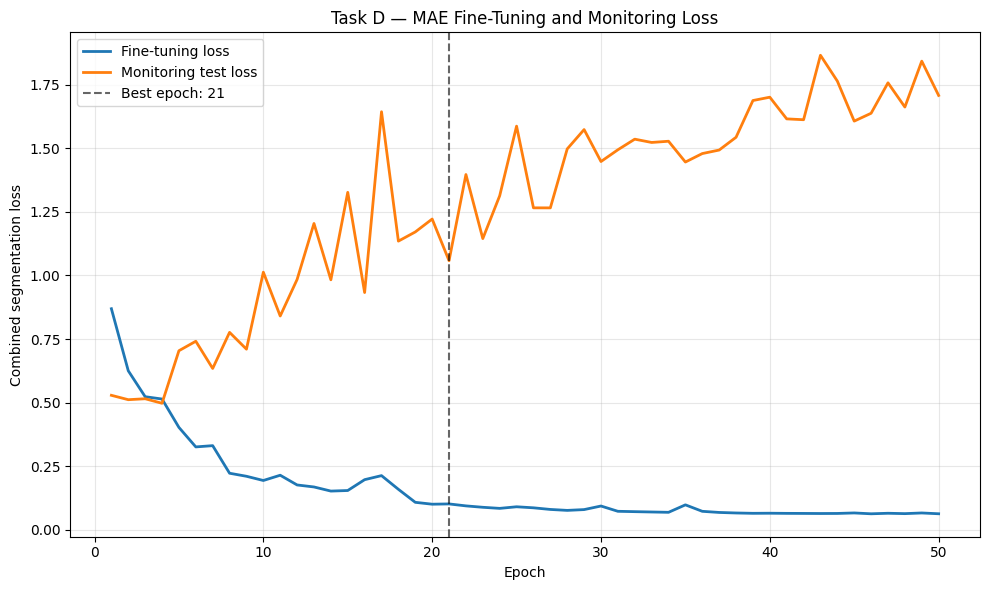

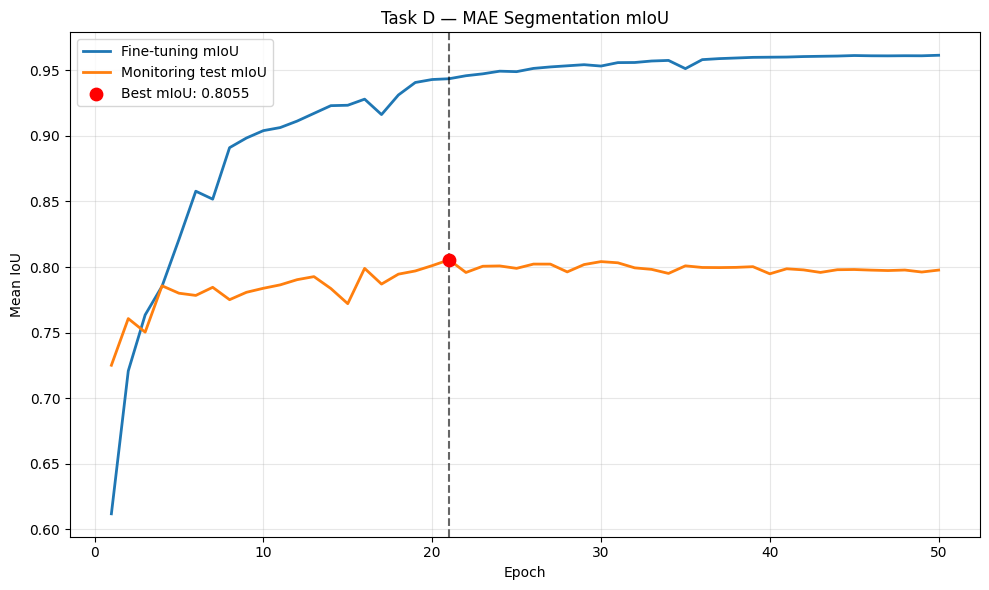

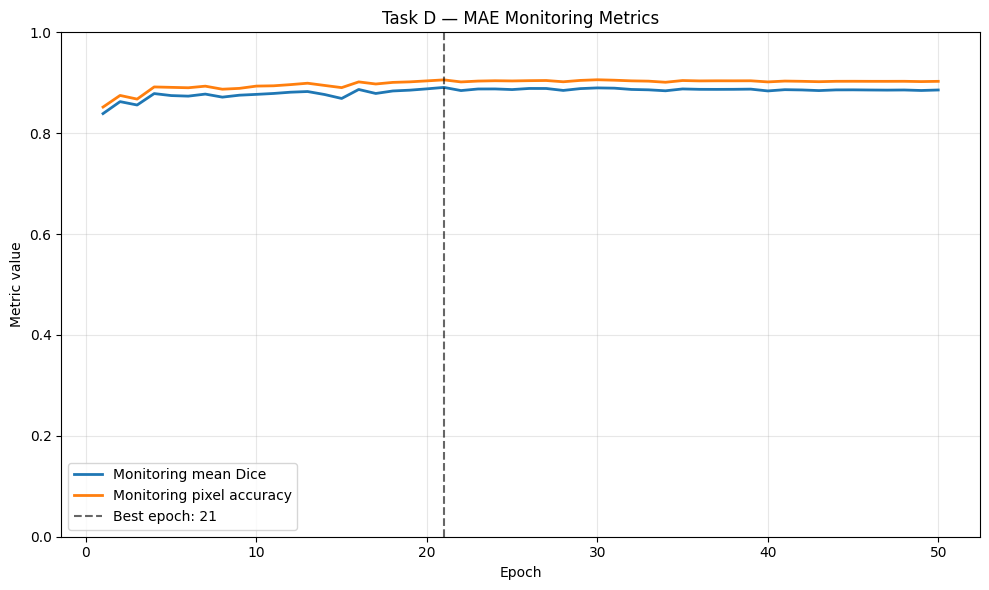

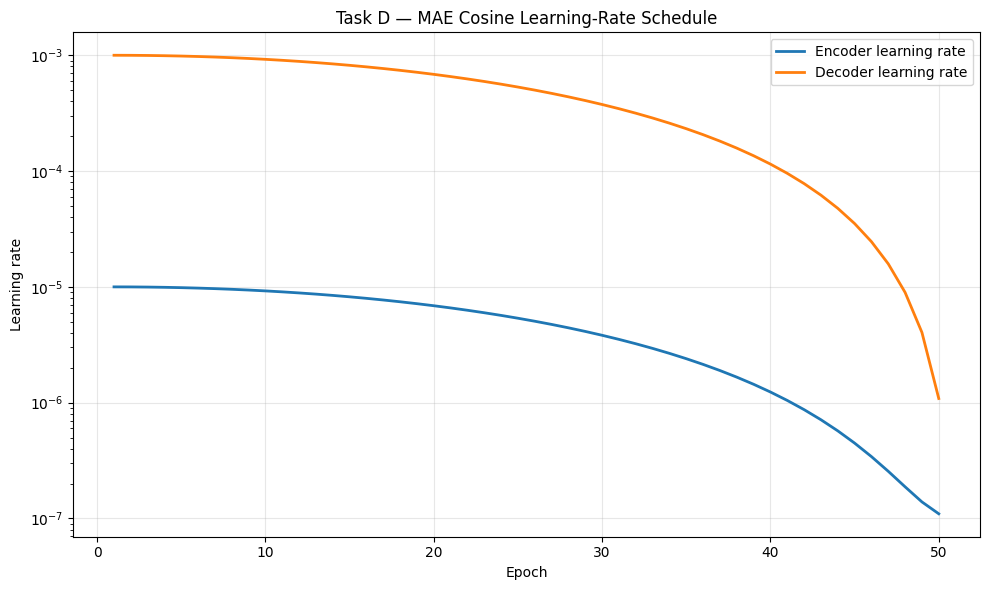


Saved Task D plots:
/kaggle/working/MAE_Downstream_outputs/mae_task_d_loss_curves.png
/kaggle/working/MAE_Downstream_outputs/mae_task_d_miou_curves.png
/kaggle/working/MAE_Downstream_outputs/mae_task_d_dice_accuracy_curves.png
/kaggle/working/MAE_Downstream_outputs/mae_task_d_learning_rate_curves.png

TASK D CELL 9 COMPLETED SUCCESSFULLY


In [10]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 9 — TRAINING HISTORY AND LEARNING CURVES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load and validate training history
# ------------------------------------------------------------
history_df = pd.read_csv(TRAINING_HISTORY_PATH)

assert len(history_df) == 50, (
    f"Expected 50 completed epochs, but found {len(history_df)}."
)

assert history_df["epoch"].tolist() == list(range(1, 51)), (
    "Training history must contain epochs 1 through 50."
)

best_history_index = history_df[
    "monitoring_mean_iou"
].idxmax()

best_history_epoch = int(
    history_df.loc[best_history_index, "epoch"]
)

best_history_miou = float(
    history_df.loc[
        best_history_index,
        "monitoring_mean_iou",
    ]
)

epoch50_history_miou = float(
    history_df.iloc[-1]["monitoring_mean_iou"]
)

print("Completed epochs:", len(history_df))
print("Best epoch:", best_history_epoch)
print("Best monitoring mIoU:", f"{best_history_miou:.6f}")
print(
    "Epoch-50 monitoring mIoU:",
    f"{epoch50_history_miou:.6f}",
)


# ------------------------------------------------------------
# 2. Plot paths
# ------------------------------------------------------------
LOSS_CURVE_PATH = OUTPUT_ROOT / "mae_task_d_loss_curves.png"

MIOU_CURVE_PATH = OUTPUT_ROOT / "mae_task_d_miou_curves.png"

DICE_ACCURACY_CURVE_PATH = (
    OUTPUT_ROOT
    / "mae_task_d_dice_accuracy_curves.png"
)

LEARNING_RATE_CURVE_PATH = (
    OUTPUT_ROOT
    / "mae_task_d_learning_rate_curves.png"
)


# ------------------------------------------------------------
# 3. Loss curves
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Fine-tuning loss",
    linewidth=2,
)

plt.plot(
    history_df["epoch"],
    history_df["monitoring_loss"],
    label="Monitoring test loss",
    linewidth=2,
)

plt.axvline(
    best_history_epoch,
    color="black",
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch: {best_history_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("Combined segmentation loss")
plt.title("Task D — MAE Fine-Tuning and Monitoring Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(LOSS_CURVE_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# 4. mIoU curves
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_mean_iou"],
    label="Fine-tuning mIoU",
    linewidth=2,
)

plt.plot(
    history_df["epoch"],
    history_df["monitoring_mean_iou"],
    label="Monitoring test mIoU",
    linewidth=2,
)

plt.scatter(
    best_history_epoch,
    best_history_miou,
    color="red",
    s=80,
    zorder=5,
    label=f"Best mIoU: {best_history_miou:.4f}",
)

plt.axvline(
    best_history_epoch,
    color="black",
    linestyle="--",
    alpha=0.6,
)

plt.xlabel("Epoch")
plt.ylabel("Mean IoU")
plt.title("Task D — MAE Segmentation mIoU")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(MIOU_CURVE_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close()


# ------------------------------------------------------------
# 5. Monitoring Dice and accuracy
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["monitoring_mean_dice"],
    label="Monitoring mean Dice",
    linewidth=2,
)

plt.plot(
    history_df["epoch"],
    history_df["monitoring_pixel_accuracy"],
    label="Monitoring pixel accuracy",
    linewidth=2,
)

plt.axvline(
    best_history_epoch,
    color="black",
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch: {best_history_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("Metric value")
plt.title("Task D — MAE Monitoring Metrics")
plt.ylim(0.0, 1.0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    DICE_ACCURACY_CURVE_PATH,
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close()


# ------------------------------------------------------------
# 6. Learning-rate curves
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.semilogy(
    history_df["epoch"],
    history_df["encoder_learning_rate"],
    label="Encoder learning rate",
    linewidth=2,
)

plt.semilogy(
    history_df["epoch"],
    history_df["decoder_learning_rate"],
    label="Decoder learning rate",
    linewidth=2,
)

plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.title("Task D — MAE Cosine Learning-Rate Schedule")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    LEARNING_RATE_CURVE_PATH,
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close()


# ------------------------------------------------------------
# 7. Verify saved plots
# ------------------------------------------------------------
saved_plot_paths = [
    LOSS_CURVE_PATH,
    MIOU_CURVE_PATH,
    DICE_ACCURACY_CURVE_PATH,
    LEARNING_RATE_CURVE_PATH,
]

print("\nSaved Task D plots:")

for plot_path in saved_plot_paths:
    assert plot_path.exists(), f"Plot was not saved: {plot_path}"
    print(plot_path)

print("\nTASK D CELL 9 COMPLETED SUCCESSFULLY")

In [11]:
# ============================================================
# TASK E — FINAL SEGMENTATION EVALUATION
# CELL 10 — LOAD BEST CHECKPOINT AND EVALUATE TEST SPLIT
# ============================================================

import json
import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# 1. Verify required artifacts
# ------------------------------------------------------------
assert BEST_CHECKPOINT_PATH.exists(), (
    f"Best checkpoint was not found: {BEST_CHECKPOINT_PATH}"
)

assert TRAINING_HISTORY_PATH.exists(), (
    f"Training history was not found: {TRAINING_HISTORY_PATH}"
)

history_df = pd.read_csv(TRAINING_HISTORY_PATH)

assert len(history_df) == 50, (
    f"Expected 50 epochs, but found {len(history_df)}."
)

history_best_index = history_df[
    "monitoring_mean_iou"
].idxmax()

history_best_epoch = int(
    history_df.loc[history_best_index, "epoch"]
)

history_best_miou = float(
    history_df.loc[
        history_best_index,
        "monitoring_mean_iou",
    ]
)


# ------------------------------------------------------------
# 2. Load the best MAE segmentation checkpoint
# ------------------------------------------------------------
best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

required_checkpoint_keys = {
    "epoch",
    "model_state_dict",
    "monitoring_mean_iou",
    "monitoring_mean_dice",
    "monitoring_pixel_accuracy",
}

missing_checkpoint_keys = (
    required_checkpoint_keys
    - set(best_checkpoint.keys())
)

assert not missing_checkpoint_keys, (
    f"Checkpoint keys are missing: {missing_checkpoint_keys}"
)

best_checkpoint_epoch = int(best_checkpoint["epoch"])

assert best_checkpoint_epoch == history_best_epoch, (
    "Best-checkpoint epoch does not match the training history."
)

mae_segmentation_model.load_state_dict(
    best_checkpoint["model_state_dict"],
    strict=True,
)

mae_segmentation_model.to(DEVICE)
mae_segmentation_model.eval()

print("=" * 72)
print("TASK E — BEST CHECKPOINT LOADED")
print("=" * 72)
print("Checkpoint:", BEST_CHECKPOINT_PATH)
print("Best epoch:", best_checkpoint_epoch)
print(
    "Recorded monitoring mIoU:",
    f"{best_checkpoint['monitoring_mean_iou']:.6f}",
)
print("Model-state loading: strict success")


# ------------------------------------------------------------
# 3. Final test evaluation
# ------------------------------------------------------------
final_evaluation = evaluate_segmentation(
    model=mae_segmentation_model,
    loader=test_loader,
    epoch_number=None,
    return_predictions=True,
)

final_predictions = (
    final_evaluation.pop("predictions")
    .to(torch.uint8)
)

final_targets = (
    final_evaluation.pop("targets")
    .to(torch.uint8)
)

final_image_ids = final_evaluation.pop("image_ids")

final_confusion = np.asarray(
    final_evaluation["confusion_matrix"],
    dtype=np.int64,
)

final_mean_iou = float(
    final_evaluation["mean_iou"]
)

final_mean_dice = float(
    final_evaluation["mean_dice"]
)

final_pixel_accuracy = float(
    final_evaluation["pixel_accuracy"]
)

final_per_class_iou = final_evaluation[
    "per_class_iou"
]

final_per_class_dice = final_evaluation[
    "per_class_dice"
]


# ------------------------------------------------------------
# 4. Consistency checks
# ------------------------------------------------------------
assert len(final_image_ids) == len(test_dataset)
assert final_predictions.shape[0] == len(test_dataset)
assert final_targets.shape[0] == len(test_dataset)

assert final_predictions.shape == final_targets.shape

assert final_predictions.shape[1:] == (
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert final_confusion.shape == (
    NUM_CLASSES,
    NUM_CLASSES,
)

assert np.isfinite(final_mean_iou)
assert np.isfinite(final_mean_dice)
assert np.isfinite(final_pixel_accuracy)

assert abs(
    final_mean_iou
    - float(best_checkpoint["monitoring_mean_iou"])
) < 1e-6, (
    "Recomputed mIoU does not match the saved checkpoint metric."
)


# ------------------------------------------------------------
# 5. Save Task E numerical results
# ------------------------------------------------------------
FINAL_METRICS_JSON_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_final_metrics.json"
)

FINAL_CLASS_METRICS_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_per_class_metrics.csv"
)

FINAL_CONFUSION_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_confusion_matrix.csv"
)

FINAL_PREDICTIONS_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_test_predictions.npz"
)

final_metrics_record = {
    "ssl_method": "MAE",
    "encoder": "ViT-Base",
    "decoder": "DeepLabV3-ASPP",
    "encoder_mode": ENCODER_MODE,
    "best_epoch": best_checkpoint_epoch,
    "fine_tuning_samples": len(finetune_dataset),
    "test_samples": len(test_dataset),
    "mean_iou": final_mean_iou,
    "mean_dice": final_mean_dice,
    "pixel_accuracy": final_pixel_accuracy,
    "background_iou": float(
        final_per_class_iou["background"]
    ),
    "landing_site_iou": float(
        final_per_class_iou["landing_site"]
    ),
    "background_dice": float(
        final_per_class_dice["background"]
    ),
    "landing_site_dice": float(
        final_per_class_dice["landing_site"]
    ),
    "test_protocol_note": (
        "The assignment-required test split was monitored "
        "during training and was also used for final evaluation. "
        "The reported best-checkpoint result may therefore be "
        "optimistic and is not an independent holdout estimate."
    ),
}

with open(FINAL_METRICS_JSON_PATH, "w") as file:
    json.dump(
        final_metrics_record,
        file,
        indent=4,
    )

class_metrics_df = pd.DataFrame(
    [
        {
            "class_id": class_id,
            "class_name": CLASS_ID_TO_NAME[class_id],
            "iou": final_per_class_iou[
                CLASS_ID_TO_NAME[class_id]
            ],
            "dice": final_per_class_dice[
                CLASS_ID_TO_NAME[class_id]
            ],
            "ground_truth_pixels": int(
                final_confusion[class_id, :].sum()
            ),
            "predicted_pixels": int(
                final_confusion[:, class_id].sum()
            ),
            "correct_pixels": int(
                final_confusion[class_id, class_id]
            ),
        }
        for class_id in range(NUM_CLASSES)
    ]
)

class_metrics_df.to_csv(
    FINAL_CLASS_METRICS_PATH,
    index=False,
)

confusion_df = pd.DataFrame(
    final_confusion,
    index=[
        f"true_{CLASS_ID_TO_NAME[class_id]}"
        for class_id in range(NUM_CLASSES)
    ],
    columns=[
        f"predicted_{CLASS_ID_TO_NAME[class_id]}"
        for class_id in range(NUM_CLASSES)
    ],
)

confusion_df.to_csv(FINAL_CONFUSION_PATH)

np.savez_compressed(
    FINAL_PREDICTIONS_PATH,
    predictions=final_predictions.numpy(),
    targets=final_targets.numpy(),
    image_ids=np.asarray(final_image_ids),
)


# ------------------------------------------------------------
# 6. Final Task E metric report
# ------------------------------------------------------------
print("\n" + "=" * 72)
print("TASK E — MAE FINAL TEST RESULTS")
print("=" * 72)
print("Selected checkpoint epoch:", best_checkpoint_epoch)
print("Test images:", len(final_image_ids))
print("Mean IoU:", f"{final_mean_iou:.6f}")
print("Mean Dice:", f"{final_mean_dice:.6f}")
print("Pixel accuracy:", f"{final_pixel_accuracy:.6f}")

print("\nPer-class IoU:")
for class_name, metric_value in final_per_class_iou.items():
    print(f"  {class_name}: {metric_value:.6f}")

print("\nPer-class Dice:")
for class_name, metric_value in final_per_class_dice.items():
    print(f"  {class_name}: {metric_value:.6f}")

print("\nConfusion matrix:")
print(final_confusion)

print("\nSaved Task E files:")
print(FINAL_METRICS_JSON_PATH)
print(FINAL_CLASS_METRICS_PATH)
print(FINAL_CONFUSION_PATH)
print(FINAL_PREDICTIONS_PATH)

assert FINAL_METRICS_JSON_PATH.exists()
assert FINAL_CLASS_METRICS_PATH.exists()
assert FINAL_CONFUSION_PATH.exists()
assert FINAL_PREDICTIONS_PATH.exists()

print("\nTASK E CELL 10 COMPLETED SUCCESSFULLY")

TASK E — BEST CHECKPOINT LOADED
Checkpoint: /kaggle/working/MAE_Downstream_outputs/checkpoints/mae_finetuned_best_segmentation.pth
Best epoch: 21
Recorded monitoring mIoU: 0.805513
Model-state loading: strict success


Task E Final Evaluation: 100%|██████████| 90/90 [00:02<00:00, 40.96it/s, loss=1.0580]



TASK E — MAE FINAL TEST RESULTS
Selected checkpoint epoch: 21
Test images: 360
Mean IoU: 0.805513
Mean Dice: 0.890810
Pixel accuracy: 0.905753

Per-class IoU:
  background: 0.871263
  landing_site: 0.739763

Per-class Dice:
  background: 0.931203
  landing_site: 0.850418

Confusion matrix:
[[15048579  1153322]
 [ 1070246  6320813]]

Saved Task E files:
/kaggle/working/MAE_Downstream_outputs/mae_task_e_final_metrics.json
/kaggle/working/MAE_Downstream_outputs/mae_task_e_per_class_metrics.csv
/kaggle/working/MAE_Downstream_outputs/mae_task_e_confusion_matrix.csv
/kaggle/working/MAE_Downstream_outputs/mae_task_e_test_predictions.npz

TASK E CELL 10 COMPLETED SUCCESSFULLY


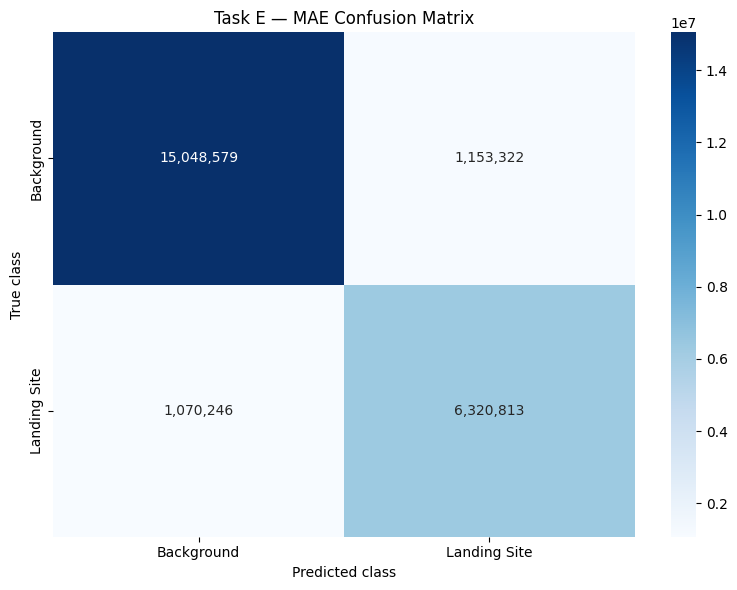

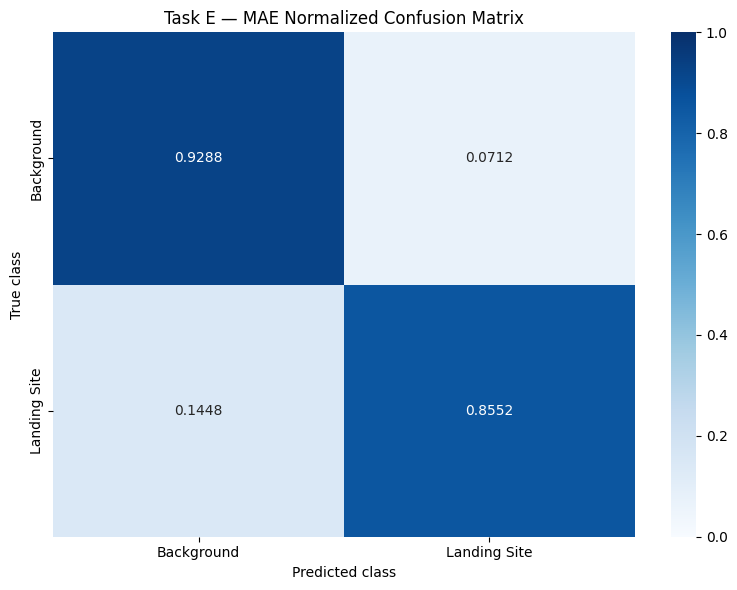

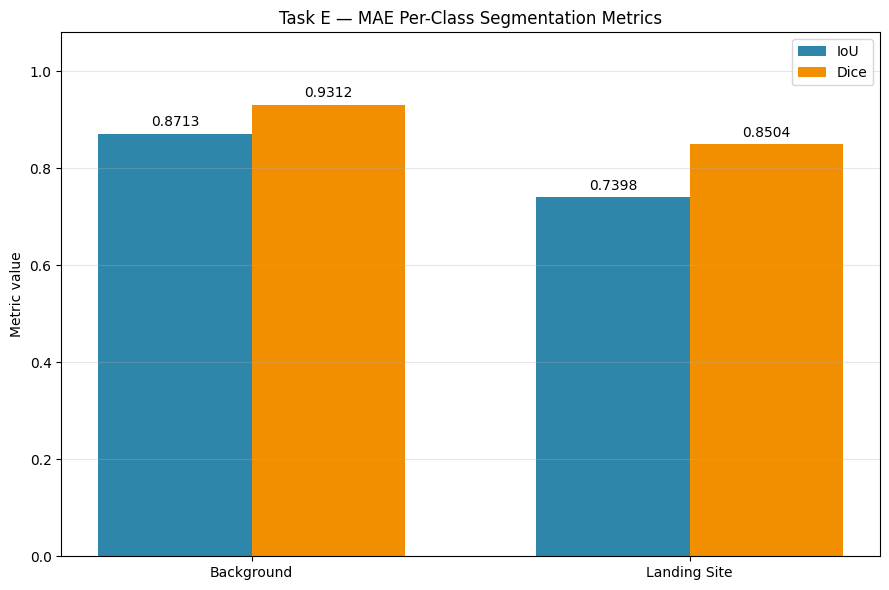

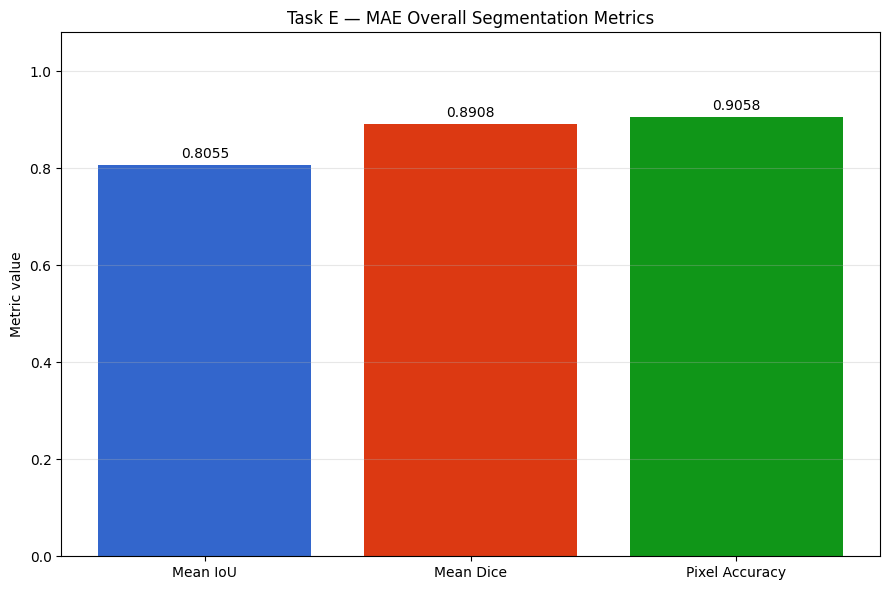

TASK E — SAVED VISUALIZATIONS
/kaggle/working/MAE_Downstream_outputs/mae_task_e_confusion_matrix.png
/kaggle/working/MAE_Downstream_outputs/mae_task_e_normalized_confusion_matrix.png
/kaggle/working/MAE_Downstream_outputs/mae_task_e_per_class_metrics.png
/kaggle/working/MAE_Downstream_outputs/mae_task_e_overall_metrics.png


In [12]:
# ============================================================
# TASK E — FINAL SEGMENTATION EVALUATION
# CELL 11 — CONFUSION MATRIX AND METRIC VISUALIZATIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# 1. Dependency checks
# ------------------------------------------------------------
assert "final_confusion" in globals(), (
    "Run Task E Cell 10 before this cell."
)

assert final_confusion.shape == (
    NUM_CLASSES,
    NUM_CLASSES,
)

class_names = [
    CLASS_ID_TO_NAME[class_id]
    .replace("_", " ")
    .title()
    for class_id in range(NUM_CLASSES)
]


# ------------------------------------------------------------
# 2. Output paths
# ------------------------------------------------------------
CONFUSION_PLOT_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_confusion_matrix.png"
)

NORMALIZED_CONFUSION_PLOT_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_normalized_confusion_matrix.png"
)

CLASS_METRICS_PLOT_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_per_class_metrics.png"
)

OVERALL_METRICS_PLOT_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_overall_metrics.png"
)


# ------------------------------------------------------------
# 3. Raw confusion matrix
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))

sns.heatmap(
    final_confusion,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Task E — MAE Confusion Matrix")
plt.tight_layout()

plt.savefig(
    CONFUSION_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 4. Row-normalized confusion matrix
# ------------------------------------------------------------
row_totals = final_confusion.sum(
    axis=1,
    keepdims=True,
)

normalized_confusion = np.divide(
    final_confusion,
    row_totals,
    out=np.zeros_like(
        final_confusion,
        dtype=np.float64,
    ),
    where=row_totals != 0,
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    normalized_confusion,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Task E — MAE Normalized Confusion Matrix")
plt.tight_layout()

plt.savefig(
    NORMALIZED_CONFUSION_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 5. Per-class IoU and Dice
# ------------------------------------------------------------
class_iou_values = [
    final_per_class_iou[
        CLASS_ID_TO_NAME[class_id]
    ]
    for class_id in range(NUM_CLASSES)
]

class_dice_values = [
    final_per_class_dice[
        CLASS_ID_TO_NAME[class_id]
    ]
    for class_id in range(NUM_CLASSES)
]

x_positions = np.arange(NUM_CLASSES)
bar_width = 0.35

plt.figure(figsize=(9, 6))

iou_bars = plt.bar(
    x_positions - bar_width / 2,
    class_iou_values,
    width=bar_width,
    label="IoU",
    color="#2E86AB",
)

dice_bars = plt.bar(
    x_positions + bar_width / 2,
    class_dice_values,
    width=bar_width,
    label="Dice",
    color="#F18F01",
)

plt.bar_label(
    iou_bars,
    fmt="%.4f",
    padding=3,
)

plt.bar_label(
    dice_bars,
    fmt="%.4f",
    padding=3,
)

plt.xticks(
    x_positions,
    class_names,
)

plt.ylabel("Metric value")
plt.ylim(0.0, 1.08)
plt.title("Task E — MAE Per-Class Segmentation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    CLASS_METRICS_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 6. Overall segmentation metrics
# ------------------------------------------------------------
overall_metric_names = [
    "Mean IoU",
    "Mean Dice",
    "Pixel Accuracy",
]

overall_metric_values = [
    final_mean_iou,
    final_mean_dice,
    final_pixel_accuracy,
]

overall_colors = [
    "#3366CC",
    "#DC3912",
    "#109618",
]

plt.figure(figsize=(9, 6))

overall_bars = plt.bar(
    overall_metric_names,
    overall_metric_values,
    color=overall_colors,
)

plt.bar_label(
    overall_bars,
    fmt="%.4f",
    padding=3,
)

plt.ylabel("Metric value")
plt.ylim(0.0, 1.08)
plt.title("Task E — MAE Overall Segmentation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OVERALL_METRICS_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 7. Verify saved visualizations
# ------------------------------------------------------------
saved_visualization_paths = [
    CONFUSION_PLOT_PATH,
    NORMALIZED_CONFUSION_PLOT_PATH,
    CLASS_METRICS_PLOT_PATH,
    OVERALL_METRICS_PLOT_PATH,
]

print("=" * 72)
print("TASK E — SAVED VISUALIZATIONS")
print("=" * 72)

for visualization_path in saved_visualization_paths:
    assert visualization_path.exists(), (
        f"Visualization was not saved: {visualization_path}"
    )
    print(visualization_path)



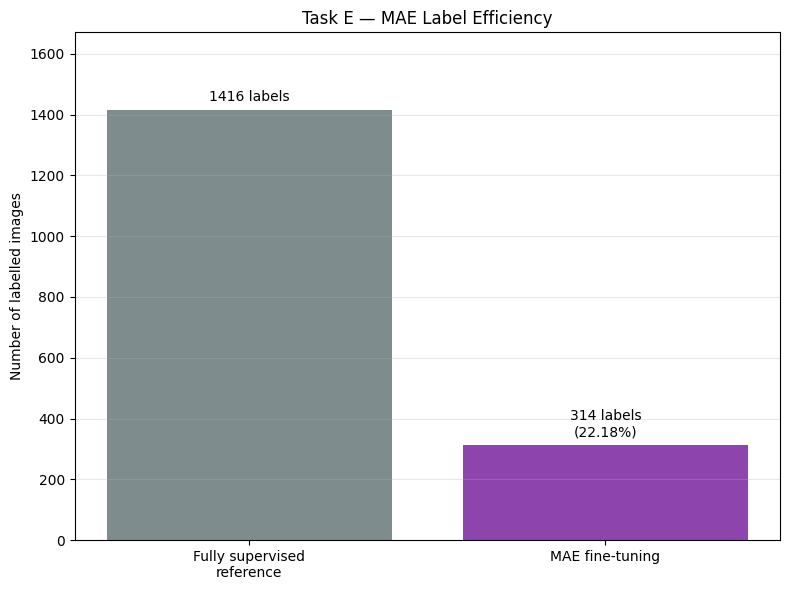

TASK E — MAE COMPARISON PACKAGE
SSL pretraining images: 1416
Labels used during SSL pretraining: 0
Labelled fine-tuning images: 314
Fully supervised reference images: 1416
Label efficiency: 22.18%
Best checkpoint epoch: 21
Best test mIoU: 0.805513
Epoch-50 test mIoU: 0.797678
Total parameters: 106,696,452
Trainable parameters: 106,696,452

Saved comparison files:
/kaggle/working/MAE_Downstream_outputs/final_comparison_input/mae_comparison_row.csv
/kaggle/working/MAE_Downstream_outputs/final_comparison_input/mae_comparison_record.json
/kaggle/working/MAE_Downstream_outputs/mae_task_e_label_efficiency.png


In [13]:
# ============================================================
# TASK E — FINAL SEGMENTATION EVALUATION
# CELL 12 — LABEL EFFICIENCY AND COMPARISON PACKAGE
# ============================================================

import json
import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Validate required Task D and Task E results
# ------------------------------------------------------------
assert "final_mean_iou" in globals(), (
    "Run Task E Cell 10 before this cell."
)

assert "final_mean_dice" in globals()
assert "final_pixel_accuracy" in globals()
assert BEST_CHECKPOINT_PATH.exists()
assert EPOCH50_CHECKPOINT_PATH.exists()

history_df = pd.read_csv(TRAINING_HISTORY_PATH)

assert len(history_df) == 50


# ------------------------------------------------------------
# 2. Label-efficiency calculation
# ------------------------------------------------------------
ssl_pretraining_images = len(train_ssl_df)
labelled_finetuning_images = len(val_finetune_df)
final_test_images = len(test_eval_df)

# Part A used the training split as the supervised training set.
fully_supervised_reference_images = ssl_pretraining_images

label_efficiency_ratio = (
    labelled_finetuning_images
    / fully_supervised_reference_images
)

label_efficiency_percent = (
    label_efficiency_ratio * 100.0
)

unlabelled_pretraining_labels_used = 0


# ------------------------------------------------------------
# 3. Model parameter counts
# ------------------------------------------------------------
total_parameter_count = sum(
    parameter.numel()
    for parameter in mae_segmentation_model.parameters()
)

trainable_parameter_count = sum(
    parameter.numel()
    for parameter in mae_segmentation_model.parameters()
    if parameter.requires_grad
)

encoder_parameter_count = sum(
    parameter.numel()
    for parameter in mae_segmentation_model.encoder.parameters()
)

decoder_parameter_count = (
    total_parameter_count
    - encoder_parameter_count
)


# ------------------------------------------------------------
# 4. Epoch-50 results
# ------------------------------------------------------------
epoch50_row = history_df.iloc[-1]

epoch50_miou = float(
    epoch50_row["monitoring_mean_iou"]
)

epoch50_mean_dice = float(
    epoch50_row["monitoring_mean_dice"]
)

epoch50_pixel_accuracy = float(
    epoch50_row["monitoring_pixel_accuracy"]
)


# ------------------------------------------------------------
# 5. Checkpoint sizes
# ------------------------------------------------------------
best_checkpoint_size_mb = (
    os.path.getsize(BEST_CHECKPOINT_PATH)
    / (1024 ** 2)
)

epoch50_checkpoint_size_mb = (
    os.path.getsize(EPOCH50_CHECKPOINT_PATH)
    / (1024 ** 2)
)


# ------------------------------------------------------------
# 6. Build comparison-ready result row
# ------------------------------------------------------------
mae_comparison_record = {
    "method": "MAE",
    "ssl_pretraining_method": "Masked Autoencoder",
    "encoder": "ViT-Base",
    "decoder": "DeepLabV3-ASPP",
    "encoder_mode": ENCODER_MODE,
    "ssl_pretraining_epochs": 50,
    "downstream_finetuning_epochs": 50,
    "ssl_pretraining_images": ssl_pretraining_images,
    "ssl_pretraining_labels_used": (
        unlabelled_pretraining_labels_used
    ),
    "labelled_finetuning_images": (
        labelled_finetuning_images
    ),
    "fully_supervised_reference_images": (
        fully_supervised_reference_images
    ),
    "label_efficiency_ratio": label_efficiency_ratio,
    "label_efficiency_percent": label_efficiency_percent,
    "final_test_images": final_test_images,
    "best_epoch": best_checkpoint_epoch,
    "best_test_mean_iou": final_mean_iou,
    "best_test_mean_dice": final_mean_dice,
    "best_test_pixel_accuracy": final_pixel_accuracy,
    "background_iou": float(
        final_per_class_iou["background"]
    ),
    "landing_site_iou": float(
        final_per_class_iou["landing_site"]
    ),
    "background_dice": float(
        final_per_class_dice["background"]
    ),
    "landing_site_dice": float(
        final_per_class_dice["landing_site"]
    ),
    "epoch50_test_mean_iou": epoch50_miou,
    "epoch50_test_mean_dice": epoch50_mean_dice,
    "epoch50_test_pixel_accuracy": (
        epoch50_pixel_accuracy
    ),
    "total_parameters": total_parameter_count,
    "trainable_parameters": trainable_parameter_count,
    "encoder_parameters": encoder_parameter_count,
    "decoder_parameters": decoder_parameter_count,
    "best_checkpoint_size_mb": best_checkpoint_size_mb,
    "epoch50_checkpoint_size_mb": (
        epoch50_checkpoint_size_mb
    ),
    "checkpoint_selection_metric": (
        "Monitoring test mean IoU"
    ),
    "evaluation_protocol": (
        "The assignment-defined test split was monitored "
        "during all 50 downstream epochs and used for final "
        "evaluation."
    ),
}


# ------------------------------------------------------------
# 7. Save comparison package
# ------------------------------------------------------------
MAE_COMPARISON_CSV_PATH = (
    COMPARISON_ROOT
    / "mae_comparison_row.csv"
)

MAE_COMPARISON_JSON_PATH = (
    COMPARISON_ROOT
    / "mae_comparison_record.json"
)

LABEL_EFFICIENCY_PLOT_PATH = (
    OUTPUT_ROOT
    / "mae_task_e_label_efficiency.png"
)

pd.DataFrame(
    [mae_comparison_record]
).to_csv(
    MAE_COMPARISON_CSV_PATH,
    index=False,
)

with open(MAE_COMPARISON_JSON_PATH, "w") as file:
    json.dump(
        mae_comparison_record,
        file,
        indent=4,
    )


# ------------------------------------------------------------
# 8. Label-efficiency visualization
# ------------------------------------------------------------
label_counts = [
    fully_supervised_reference_images,
    labelled_finetuning_images,
]

label_names = [
    "Fully supervised\nreference",
    "MAE fine-tuning",
]

label_colors = [
    "#7F8C8D",
    "#8E44AD",
]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    label_names,
    label_counts,
    color=label_colors,
)

plt.bar_label(
    bars,
    labels=[
        f"{fully_supervised_reference_images} labels",
        (
            f"{labelled_finetuning_images} labels\n"
            f"({label_efficiency_percent:.2f}%)"
        ),
    ],
    padding=4,
)

plt.ylabel("Number of labelled images")
plt.title("Task E — MAE Label Efficiency")
plt.ylim(
    0,
    max(label_counts) * 1.18,
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    LABEL_EFFICIENCY_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 9. Task E summary
# ------------------------------------------------------------
print("=" * 72)
print("TASK E — MAE COMPARISON PACKAGE")
print("=" * 72)
print("SSL pretraining images:", ssl_pretraining_images)
print(
    "Labels used during SSL pretraining:",
    unlabelled_pretraining_labels_used,
)
print(
    "Labelled fine-tuning images:",
    labelled_finetuning_images,
)
print(
    "Fully supervised reference images:",
    fully_supervised_reference_images,
)
print(
    "Label efficiency:",
    f"{label_efficiency_percent:.2f}%",
)
print("Best checkpoint epoch:", best_checkpoint_epoch)
print("Best test mIoU:", f"{final_mean_iou:.6f}")
print("Epoch-50 test mIoU:", f"{epoch50_miou:.6f}")
print("Total parameters:", f"{total_parameter_count:,}")
print("Trainable parameters:", f"{trainable_parameter_count:,}")

print("\nSaved comparison files:")
print(MAE_COMPARISON_CSV_PATH)
print(MAE_COMPARISON_JSON_PATH)
print(LABEL_EFFICIENCY_PLOT_PATH)

assert MAE_COMPARISON_CSV_PATH.exists()
assert MAE_COMPARISON_JSON_PATH.exists()
assert LABEL_EFFICIENCY_PLOT_PATH.exists()



In [14]:
# ============================================================
# TASK F — ERROR ANALYSIS
# CELL 13 — IDENTIFY WORST MAE TEST IMAGES
# ============================================================

import numpy as np
import pandas as pd
from tqdm import tqdm


# ------------------------------------------------------------
# 1. Verify Task E predictions
# ------------------------------------------------------------
assert "final_predictions" in globals(), (
    "Run Task E Cell 10 before this cell."
)

assert "final_targets" in globals()
assert "final_image_ids" in globals()

assert len(final_image_ids) == len(test_eval_df)
assert final_predictions.shape == final_targets.shape

NUM_WORST_IMAGES = 8


# ------------------------------------------------------------
# 2. Per-image metric function
# ------------------------------------------------------------
def calculate_per_image_metrics(
    prediction,
    target,
    num_classes=NUM_CLASSES,
):
    prediction = np.asarray(
        prediction,
        dtype=np.uint8,
    )

    target = np.asarray(
        target,
        dtype=np.uint8,
    )

    encoded_pairs = (
        target.reshape(-1).astype(np.int64)
        * num_classes
        + prediction.reshape(-1).astype(np.int64)
    )

    confusion = np.bincount(
        encoded_pairs,
        minlength=num_classes ** 2,
    ).reshape(num_classes, num_classes)

    true_positive = np.diag(confusion).astype(
        np.float64
    )

    ground_truth_total = confusion.sum(
        axis=1
    ).astype(np.float64)

    prediction_total = confusion.sum(
        axis=0
    ).astype(np.float64)

    union = (
        ground_truth_total
        + prediction_total
        - true_positive
    )

    iou = np.divide(
        true_positive,
        union,
        out=np.full(
            num_classes,
            np.nan,
            dtype=np.float64,
        ),
        where=union > 0,
    )

    dice_denominator = (
        ground_truth_total
        + prediction_total
    )

    dice = np.divide(
        2.0 * true_positive,
        dice_denominator,
        out=np.full(
            num_classes,
            np.nan,
            dtype=np.float64,
        ),
        where=dice_denominator > 0,
    )

    pixel_accuracy = (
        true_positive.sum()
        / confusion.sum()
    )

    false_positive_pixels = int(confusion[0, 1])
    false_negative_pixels = int(confusion[1, 0])

    total_pixels = int(confusion.sum())

    return {
        "mean_iou": float(np.nanmean(iou)),
        "background_iou": float(iou[0]),
        "landing_site_iou": float(iou[1]),
        "mean_dice": float(np.nanmean(dice)),
        "background_dice": float(dice[0]),
        "landing_site_dice": float(dice[1]),
        "pixel_accuracy": float(pixel_accuracy),
        "gt_foreground_fraction": float(
            ground_truth_total[1] / total_pixels
        ),
        "predicted_foreground_fraction": float(
            prediction_total[1] / total_pixels
        ),
        "false_positive_fraction": float(
            false_positive_pixels / total_pixels
        ),
        "false_negative_fraction": float(
            false_negative_pixels / total_pixels
        ),
        "error_pixel_fraction": float(
            (
                false_positive_pixels
                + false_negative_pixels
            )
            / total_pixels
        ),
        "gt_has_landing_site": bool(
            ground_truth_total[1] > 0
        ),
        "predicted_has_landing_site": bool(
            prediction_total[1] > 0
        ),
        "true_background_pixels": int(
            confusion[0, 0]
        ),
        "false_positive_pixels": (
            false_positive_pixels
        ),
        "false_negative_pixels": (
            false_negative_pixels
        ),
        "true_landing_site_pixels": int(
            confusion[1, 1]
        ),
    }


# ------------------------------------------------------------
# 3. Calculate metrics for every test image
# ------------------------------------------------------------
per_image_records = []

prediction_array = final_predictions.numpy()
target_array = final_targets.numpy()

for index in tqdm(
    range(len(final_image_ids)),
    desc="Inspecting MAE test predictions",
):
    image_metrics = calculate_per_image_metrics(
        prediction=prediction_array[index],
        target=target_array[index],
    )

    corresponding_row = test_eval_df.iloc[index]

    record = {
        "dataset_index": index,
        "image_id": str(final_image_ids[index]),
        "image_relpath": corresponding_row[
            "image_relpath"
        ],
        "encoded_mask_relpath": corresponding_row[
            "encoded_mask_relpath"
        ],
        **image_metrics,
    }

    per_image_records.append(record)


all_test_image_metrics_df = pd.DataFrame(
    per_image_records
)

assert len(all_test_image_metrics_df) == len(
    test_eval_df
)

assert (
    all_test_image_metrics_df["image_id"].tolist()
    == [str(image_id) for image_id in final_image_ids]
), "Prediction and metadata ordering do not match."


# ------------------------------------------------------------
# 4. Select meaningful worst cases
# ------------------------------------------------------------
landing_site_cases_df = all_test_image_metrics_df[
    all_test_image_metrics_df[
        "gt_has_landing_site"
    ]
].copy()

assert len(landing_site_cases_df) >= NUM_WORST_IMAGES, (
    "There are not enough landing-site cases."
)

worst_test_images_df = (
    landing_site_cases_df
    .sort_values(
        by=[
            "mean_iou",
            "landing_site_iou",
            "pixel_accuracy",
        ],
        ascending=[True, True, True],
    )
    .head(NUM_WORST_IMAGES)
    .reset_index(drop=True)
)

worst_test_images_df.insert(
    0,
    "error_rank",
    np.arange(1, len(worst_test_images_df) + 1),
)


# ------------------------------------------------------------
# 5. Save Task F tables
# ------------------------------------------------------------
ALL_TEST_IMAGE_METRICS_PATH = (
    OUTPUT_ROOT
    / "mae_task_f_all_test_images.csv"
)

WORST_TEST_IMAGES_PATH = (
    OUTPUT_ROOT
    / "mae_task_f_worst_test_images.csv"
)

all_test_image_metrics_df.to_csv(
    ALL_TEST_IMAGE_METRICS_PATH,
    index=False,
)

worst_test_images_df.to_csv(
    WORST_TEST_IMAGES_PATH,
    index=False,
)


# ------------------------------------------------------------
# 6. Report selected worst cases
# ------------------------------------------------------------
display_columns = [
    "error_rank",
    "image_id",
    "mean_iou",
    "landing_site_iou",
    "background_iou",
    "mean_dice",
    "pixel_accuracy",
    "gt_foreground_fraction",
    "predicted_foreground_fraction",
    "false_positive_fraction",
    "false_negative_fraction",
]

print("=" * 72)
print("TASK F — WORST MAE TEST IMAGES")
print("=" * 72)

display(
    worst_test_images_df[display_columns]
)

print(
    "\nWorst mIoU:",
    f"{worst_test_images_df['mean_iou'].min():.6f}",
)

print(
    "Highest mIoU among selected worst cases:",
    f"{worst_test_images_df['mean_iou'].max():.6f}",
)

print(
    "\nSelected cases with a landing site:",
    int(
        worst_test_images_df[
            "gt_has_landing_site"
        ].sum()
    ),
    "/",
    len(worst_test_images_df),
)

print("\nSaved complete per-image table:")
print(ALL_TEST_IMAGE_METRICS_PATH)

print("\nSaved worst-image table:")
print(WORST_TEST_IMAGES_PATH)

assert ALL_TEST_IMAGE_METRICS_PATH.exists()
assert WORST_TEST_IMAGES_PATH.exists()
assert len(worst_test_images_df) == NUM_WORST_IMAGES



Inspecting MAE test predictions: 100%|██████████| 360/360 [00:00<00:00, 1810.03it/s]


TASK F — WORST MAE TEST IMAGES


,error_rank,image_id,mean_iou,landing_site_iou,background_iou,mean_dice,pixel_accuracy,gt_foreground_fraction,predicted_foreground_fraction,false_positive_fraction,false_negative_fraction
0,1,testing_00047,0.141536,0.229660,0.053412,0.237471,0.261749,0.951111,0.227325,0.007233,0.731018
1,2,testing_00088,0.207199,0.000000,0.414398,0.292986,0.414398,0.585602,0.000000,0.000000,0.585602
2,3,testing_00221,0.236238,0.163992,0.308484,0.376645,0.391083,0.122559,0.725250,0.605804,0.003113
3,4,testing_00205,0.262444,0.000000,0.524887,0.344214,0.524887,0.475113,0.000000,0.000000,0.475113
4,5,testing_00149,0.270853,0.462041,0.079666,0.389812,0.485977,0.936066,0.460922,0.019440,0.494583
5,6,testing_00038,0.321203,0.429882,0.212524,0.475916,0.505905,0.826736,0.412476,0.039917,0.454178
6,7,testing_00232,0.333348,0.199262,0.467434,0.484692,0.529755,0.566833,0.137451,0.020432,0.449814
7,8,testing_00172,0.338518,0.119439,0.557597,0.464681,0.582642,0.471237,0.059341,0.002731,0.414627



Worst mIoU: 0.141536
Highest mIoU among selected worst cases: 0.338518

Selected cases with a landing site: 8 / 8

Saved complete per-image table:
/kaggle/working/MAE_Downstream_outputs/mae_task_f_all_test_images.csv

Saved worst-image table:
/kaggle/working/MAE_Downstream_outputs/mae_task_f_worst_test_images.csv


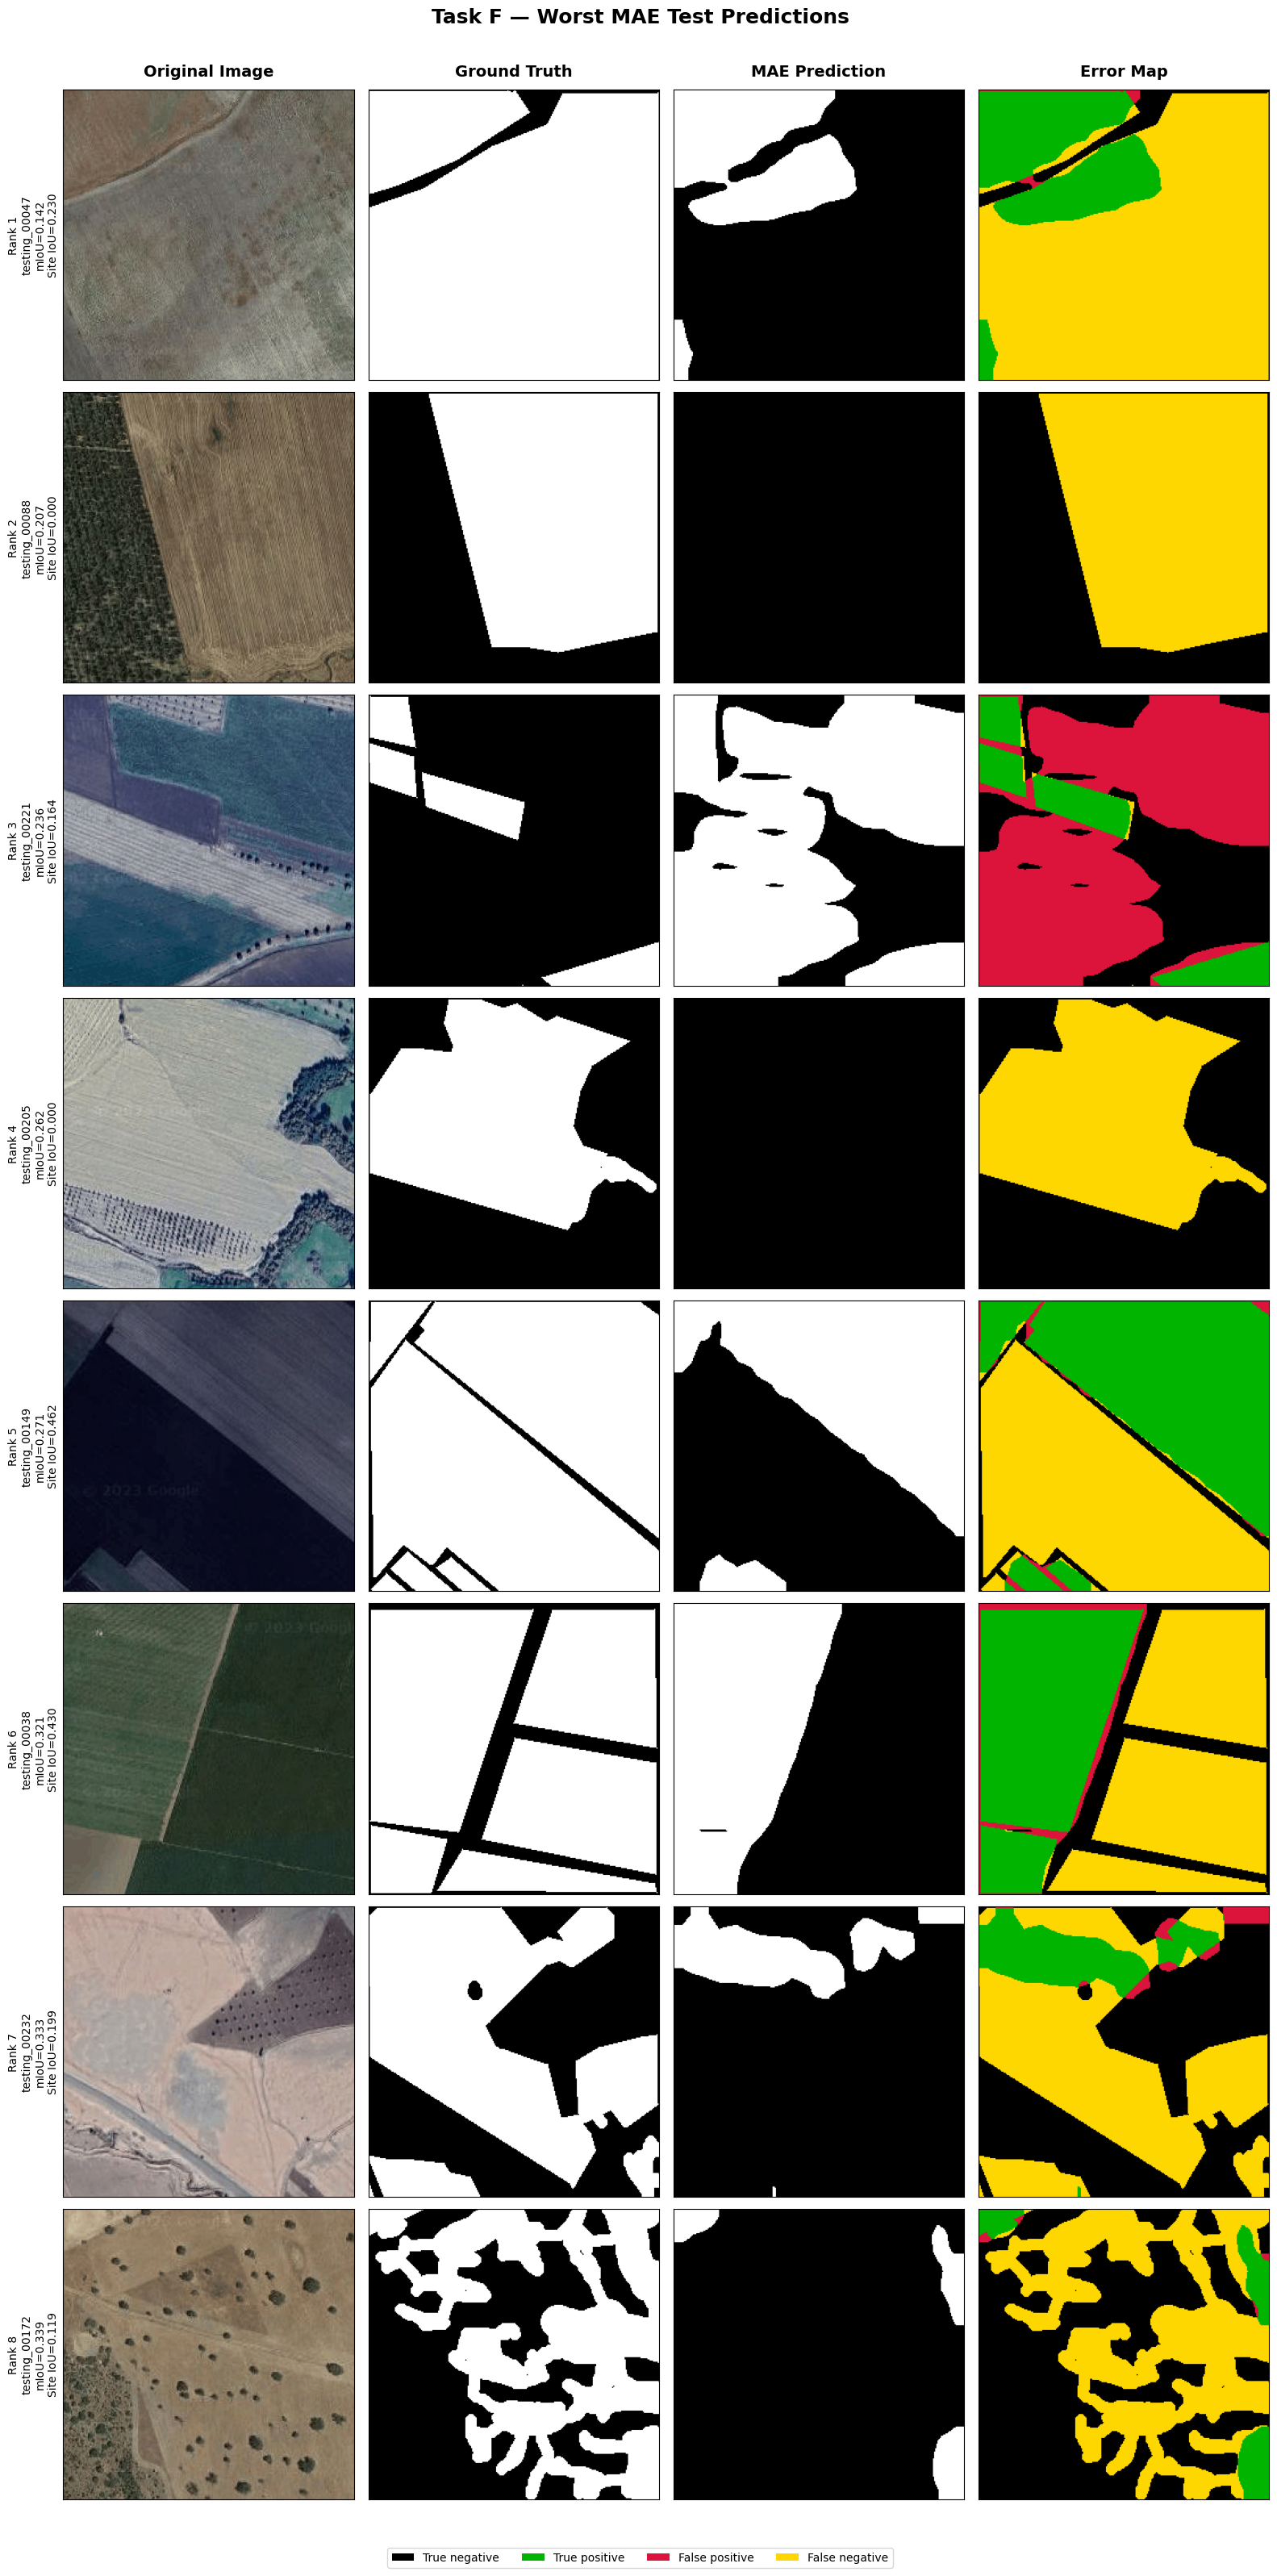

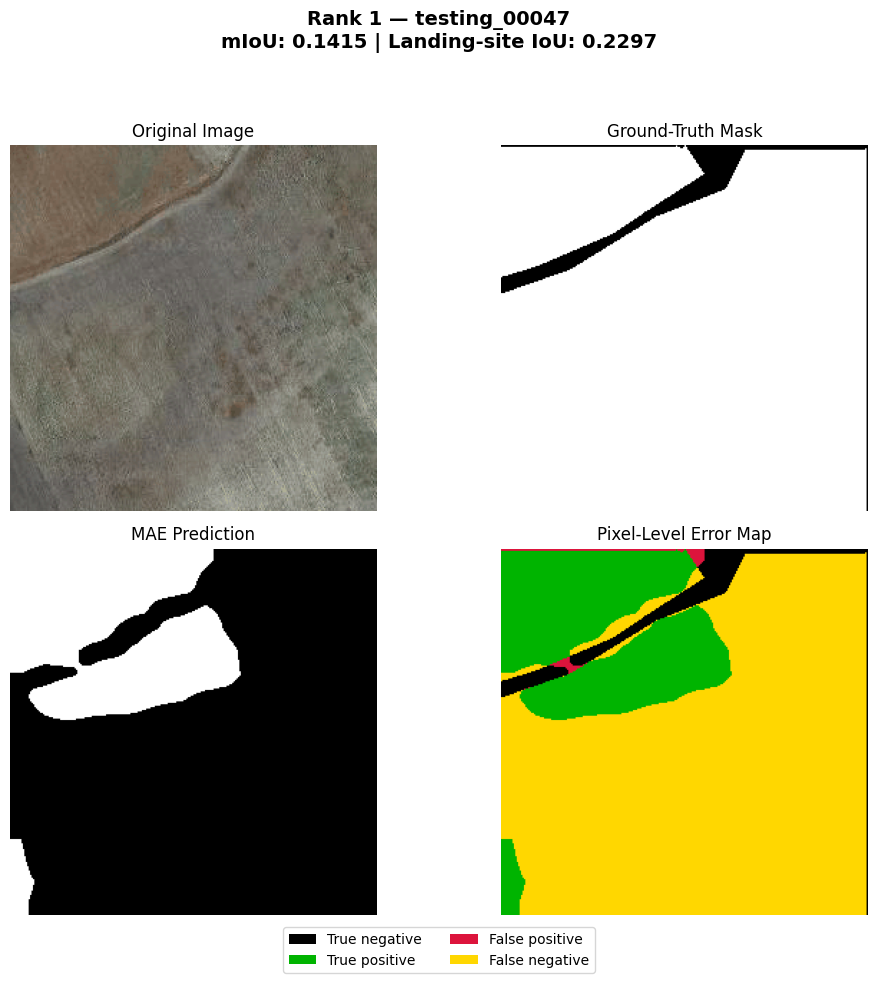

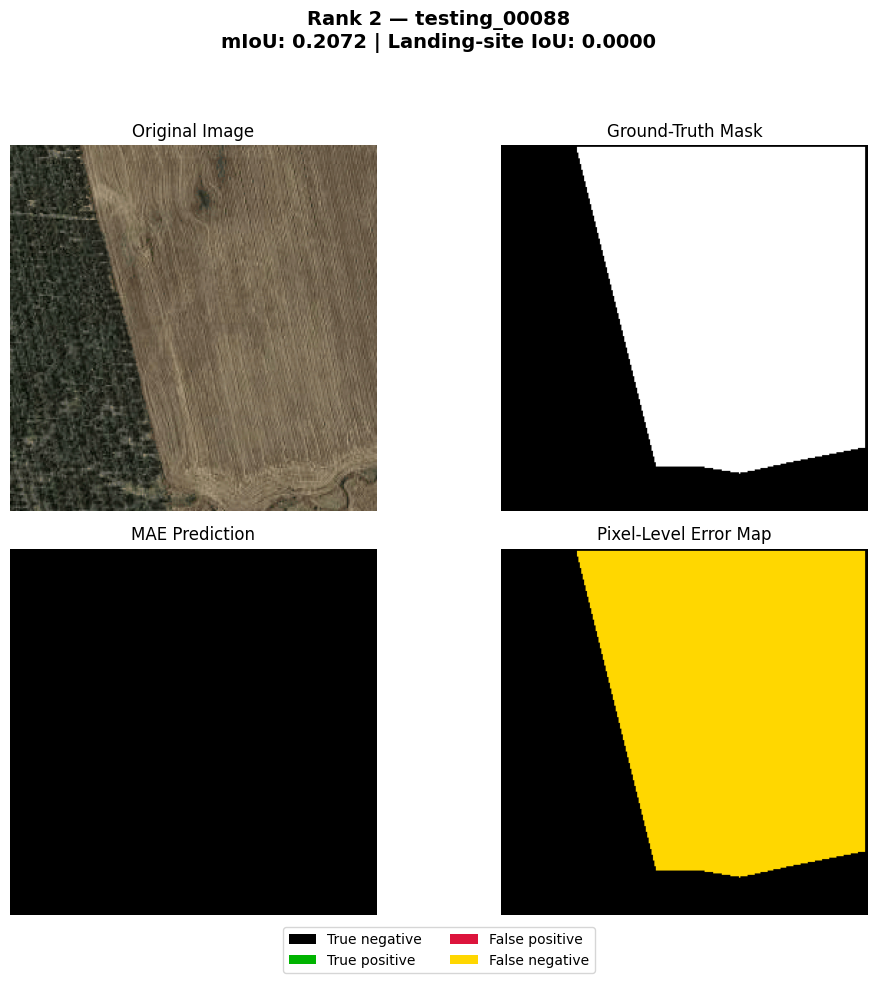

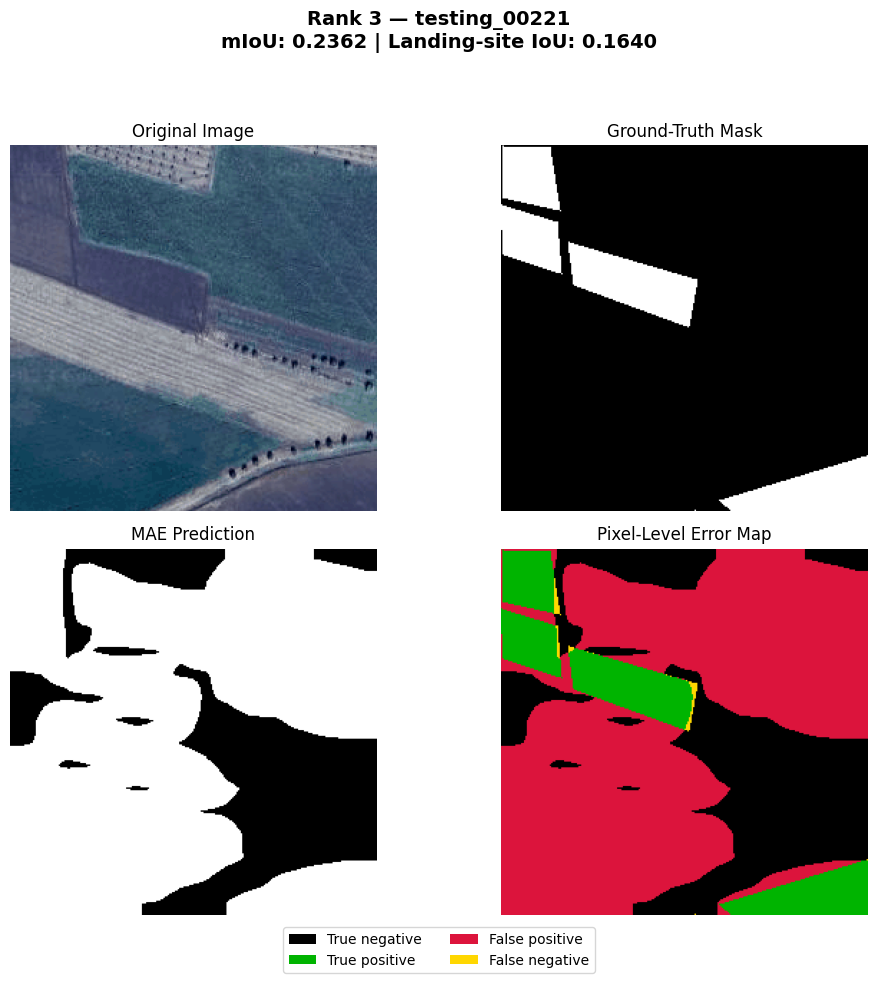

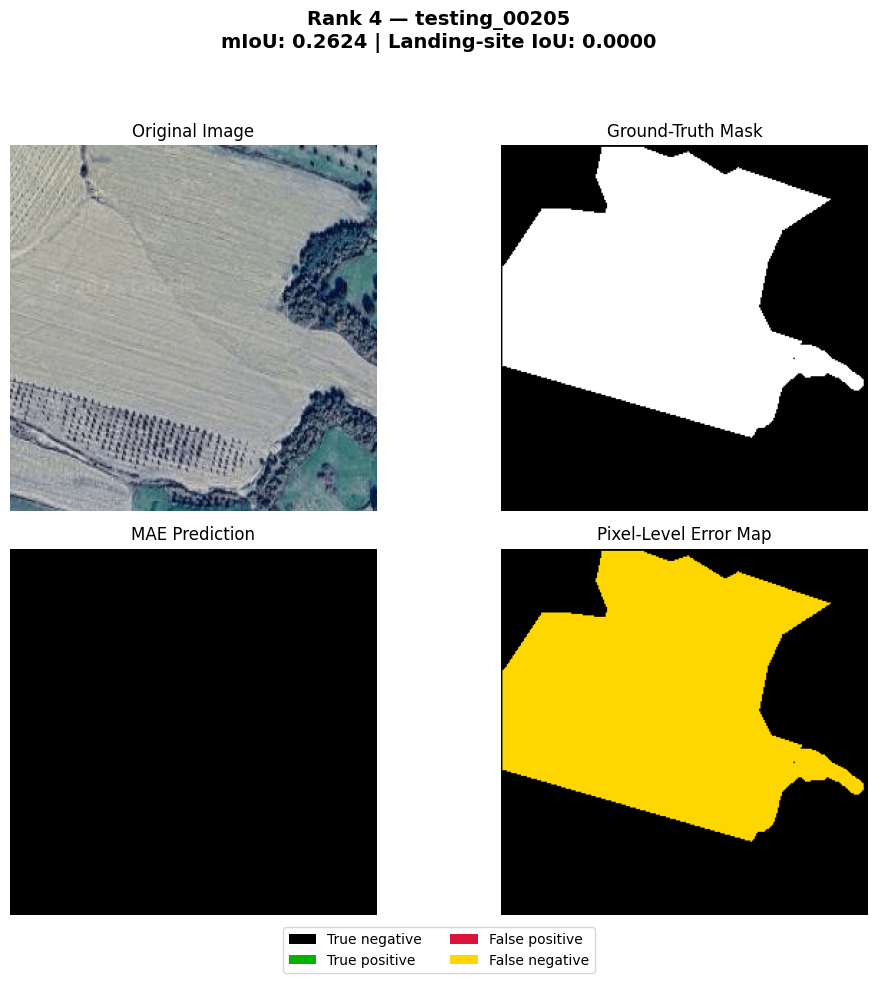

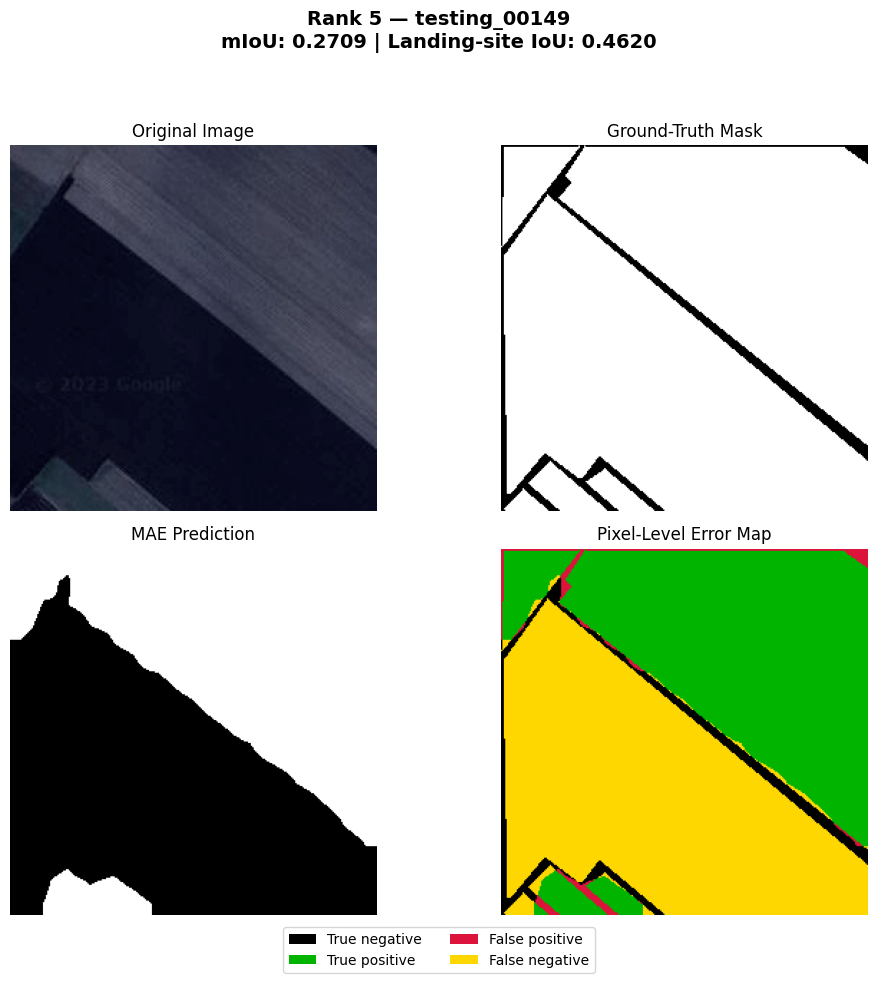

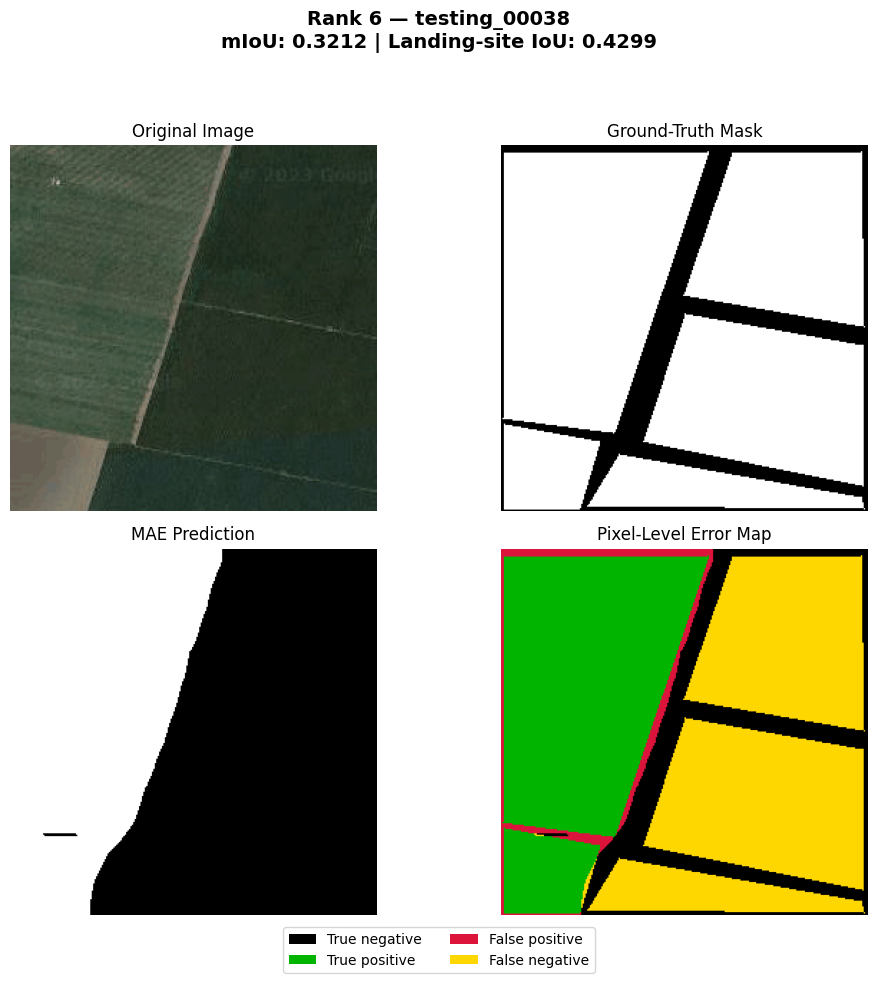

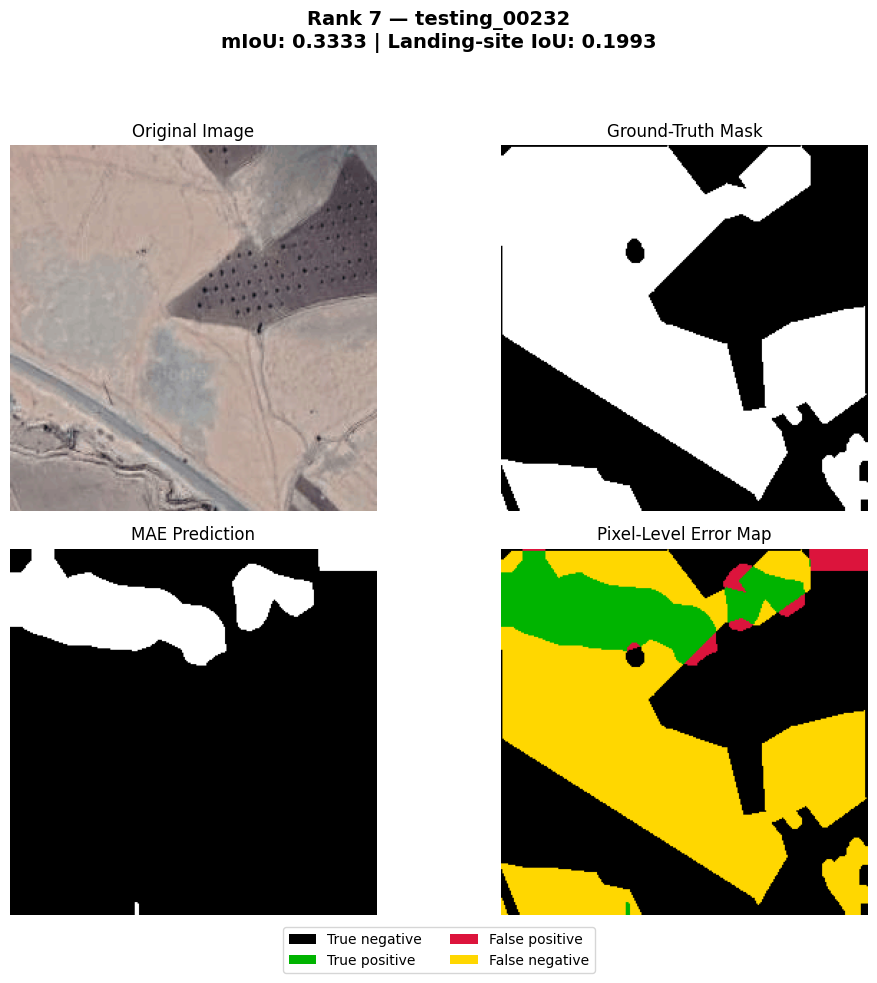

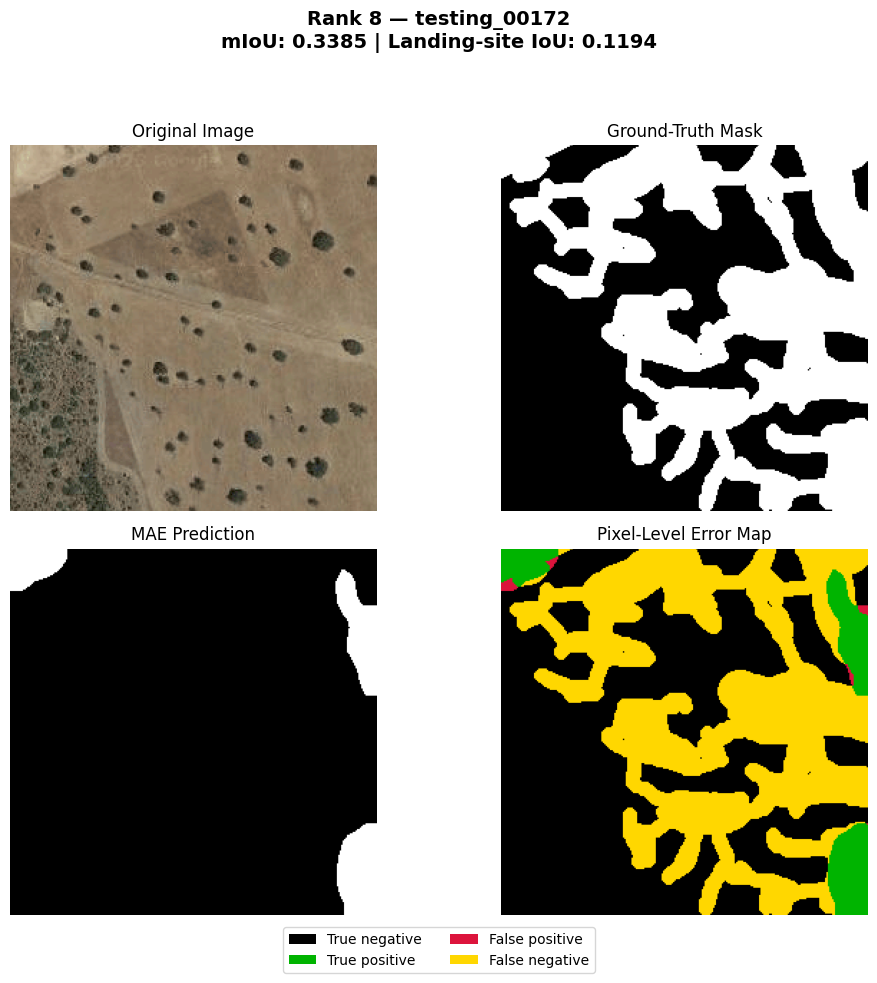

TASK F — ERROR VISUALIZATIONS SAVED

Combined grid:
/kaggle/working/MAE_Downstream_outputs/mae_task_f_worst_cases_grid.png

Individual visualizations:
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_01_testing_00047.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_02_testing_00088.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_03_testing_00221.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_04_testing_00205.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_05_testing_00149.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_06_testing_00038.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_07_testing_00232.png
/kaggle/working/MAE_Downstream_outputs/task_f_worst_case_visualizations/rank_08_testing_00172.png

Error-map colors:
Black: true negative
Green: true positive
Red:

In [15]:
# ============================================================
# TASK F — ERROR ANALYSIS
# CELL 14 — VISUALIZE WORST MAE TEST PREDICTIONS
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image


# ------------------------------------------------------------
# 1. Validate Task F inputs
# ------------------------------------------------------------
assert "worst_test_images_df" in globals(), (
    "Run Task F Cell 13 before this cell."
)

assert len(worst_test_images_df) == NUM_WORST_IMAGES
assert "final_predictions" in globals()
assert "final_targets" in globals()

TASK_F_VISUALIZATION_ROOT = (
    OUTPUT_ROOT
    / "task_f_worst_case_visualizations"
)

TASK_F_VISUALIZATION_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

WORST_CASE_GRID_PATH = (
    OUTPUT_ROOT
    / "mae_task_f_worst_cases_grid.png"
)


# ------------------------------------------------------------
# 2. Image and error-map functions
# ------------------------------------------------------------
def load_display_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.Resampling.BILINEAR,
        )

        return np.asarray(image)


def create_error_map(prediction, target):
    prediction = np.asarray(prediction)
    target = np.asarray(target)

    error_map = np.zeros(
        (
            target.shape[0],
            target.shape[1],
            3,
        ),
        dtype=np.uint8,
    )

    true_negative = (
        (target == 0)
        & (prediction == 0)
    )

    true_positive = (
        (target == 1)
        & (prediction == 1)
    )

    false_positive = (
        (target == 0)
        & (prediction == 1)
    )

    false_negative = (
        (target == 1)
        & (prediction == 0)
    )

    error_map[true_negative] = [0, 0, 0]
    error_map[true_positive] = [0, 180, 0]
    error_map[false_positive] = [220, 20, 60]
    error_map[false_negative] = [255, 215, 0]

    return error_map


error_legend = [
    Patch(
        facecolor=np.array([0, 0, 0]) / 255,
        label="True negative",
    ),
    Patch(
        facecolor=np.array([0, 180, 0]) / 255,
        label="True positive",
    ),
    Patch(
        facecolor=np.array([220, 20, 60]) / 255,
        label="False positive",
    ),
    Patch(
        facecolor=np.array([255, 215, 0]) / 255,
        label="False negative",
    ),
]


# ------------------------------------------------------------
# 3. Prepare all selected cases
# ------------------------------------------------------------
visualization_cases = []

for _, row in worst_test_images_df.iterrows():
    dataset_index = int(row["dataset_index"])

    image_path = (
        RAW_DATA_ROOT
        / row["image_relpath"]
    )

    assert image_path.exists(), (
        f"Image was not found: {image_path}"
    )

    original_image = load_display_image(
        image_path
    )

    ground_truth = (
        final_targets[dataset_index]
        .numpy()
        .astype(np.uint8)
    )

    prediction = (
        final_predictions[dataset_index]
        .numpy()
        .astype(np.uint8)
    )

    error_map = create_error_map(
        prediction=prediction,
        target=ground_truth,
    )

    visualization_cases.append(
        {
            "rank": int(row["error_rank"]),
            "image_id": str(row["image_id"]),
            "mean_iou": float(row["mean_iou"]),
            "landing_site_iou": float(
                row["landing_site_iou"]
            ),
            "original_image": original_image,
            "ground_truth": ground_truth,
            "prediction": prediction,
            "error_map": error_map,
        }
    )


# ------------------------------------------------------------
# 4. Create combined worst-case grid
# ------------------------------------------------------------
figure, axes = plt.subplots(
    nrows=NUM_WORST_IMAGES,
    ncols=4,
    figsize=(16, 4 * NUM_WORST_IMAGES),
)

column_titles = [
    "Original Image",
    "Ground Truth",
    "MAE Prediction",
    "Error Map",
]

for column_index, title in enumerate(column_titles):
    axes[0, column_index].set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

for row_index, case in enumerate(visualization_cases):
    axes[row_index, 0].imshow(
        case["original_image"]
    )

    axes[row_index, 1].imshow(
        case["ground_truth"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[row_index, 2].imshow(
        case["prediction"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[row_index, 3].imshow(
        case["error_map"]
    )

    axes[row_index, 0].set_ylabel(
        (
            f"Rank {case['rank']}\n"
            f"{case['image_id']}\n"
            f"mIoU={case['mean_iou']:.3f}\n"
            f"Site IoU={case['landing_site_iou']:.3f}"
        ),
        fontsize=10,
    )

    for column_index in range(4):
        axes[row_index, column_index].set_xticks([])
        axes[row_index, column_index].set_yticks([])

figure.suptitle(
    "Task F — Worst MAE Test Predictions",
    fontsize=18,
    fontweight="bold",
    y=0.995,
)

figure.legend(
    handles=error_legend,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.001),
)

plt.tight_layout(
    rect=[0, 0.025, 1, 0.99]
)

plt.savefig(
    WORST_CASE_GRID_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 5. Save an individual figure for every worst case
# ------------------------------------------------------------
individual_visualization_paths = []

for case in visualization_cases:
    individual_path = (
        TASK_F_VISUALIZATION_ROOT
        / (
            f"rank_{case['rank']:02d}_"
            f"{case['image_id']}.png"
        )
    )

    figure, axes = plt.subplots(
        2,
        2,
        figsize=(10, 10),
    )

    axes[0, 0].imshow(case["original_image"])
    axes[0, 0].set_title("Original Image")

    axes[0, 1].imshow(
        case["ground_truth"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[0, 1].set_title("Ground-Truth Mask")

    axes[1, 0].imshow(
        case["prediction"],
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1, 0].set_title("MAE Prediction")

    axes[1, 1].imshow(case["error_map"])
    axes[1, 1].set_title("Pixel-Level Error Map")

    for axis in axes.flat:
        axis.axis("off")

    figure.suptitle(
        (
            f"Rank {case['rank']} — {case['image_id']}\n"
            f"mIoU: {case['mean_iou']:.4f} | "
            f"Landing-site IoU: "
            f"{case['landing_site_iou']:.4f}"
        ),
        fontsize=14,
        fontweight="bold",
    )

    figure.legend(
        handles=error_legend,
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, 0.01),
    )

    plt.tight_layout(
        rect=[0, 0.06, 1, 0.94]
    )

    plt.savefig(
        individual_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    individual_visualization_paths.append(
        individual_path
    )


# ------------------------------------------------------------
# 6. Verify saved Task F figures
# ------------------------------------------------------------
assert WORST_CASE_GRID_PATH.exists()

assert len(
    individual_visualization_paths
) == NUM_WORST_IMAGES

for individual_path in individual_visualization_paths:
    assert individual_path.exists()

print("=" * 72)
print("TASK F — ERROR VISUALIZATIONS SAVED")
print("=" * 72)

print("\nCombined grid:")
print(WORST_CASE_GRID_PATH)

print("\nIndividual visualizations:")
for individual_path in individual_visualization_paths:
    print(individual_path)

print("\nError-map colors:")
print("Black: true negative")
print("Green: true positive")
print("Red: false positive")
print("Yellow: false negative")

print("\nTASK F  COMPLETED SUCCESSFULLY")

In [16]:
# ============================================================
# TASK F — FINAL NOTEBOOK VALIDATION
# CELL 15 — TASK C-F COMPLETION AUDIT AND ARTIFACT MANIFEST
# ============================================================

# AI assistance was used for code structuring and debugging;
# all reported results were generated by executing this notebook.

import json
import os
from pathlib import Path
import pandas as pd
import torch


# ------------------------------------------------------------
# 1. Validate Task C
# ------------------------------------------------------------
task_c_checks = {
    "mae_pretraining_checkpoint_found": (
        Path(MAE_ENCODER_PATH).exists()
    ),
    "mae_encoder_created": (
        "mae_encoder" in globals()
    ),
    "segmentation_model_created": (
        "mae_segmentation_model" in globals()
    ),
    "encoder_mode_defined": (
        "ENCODER_MODE" in globals()
    ),
}

assert all(task_c_checks.values()), (
    f"Task C validation failed: {task_c_checks}"
)


# ------------------------------------------------------------
# 2. Validate Task D
# ------------------------------------------------------------
history_df = pd.read_csv(TRAINING_HISTORY_PATH)

task_d_checks = {
    "history_found": TRAINING_HISTORY_PATH.exists(),
    "exactly_50_epochs": len(history_df) == 50,
    "epochs_are_1_to_50": (
        history_df["epoch"].tolist()
        == list(range(1, 51))
    ),
    "best_checkpoint_found": (
        BEST_CHECKPOINT_PATH.exists()
    ),
    "epoch50_checkpoint_found": (
        EPOCH50_CHECKPOINT_PATH.exists()
    ),
    "training_config_found": (
        TRAINING_CONFIG_PATH.exists()
    ),
    "loss_curve_found": LOSS_CURVE_PATH.exists(),
    "miou_curve_found": MIOU_CURVE_PATH.exists(),
    "dice_accuracy_curve_found": (
        DICE_ACCURACY_CURVE_PATH.exists()
    ),
    "learning_rate_curve_found": (
        LEARNING_RATE_CURVE_PATH.exists()
    ),
}

assert all(task_d_checks.values()), (
    f"Task D validation failed: {task_d_checks}"
)


# ------------------------------------------------------------
# 3. Validate Task E
# ------------------------------------------------------------
task_e_checks = {
    "final_metrics_found": (
        FINAL_METRICS_JSON_PATH.exists()
    ),
    "per_class_metrics_found": (
        FINAL_CLASS_METRICS_PATH.exists()
    ),
    "confusion_csv_found": (
        FINAL_CONFUSION_PATH.exists()
    ),
    "predictions_found": (
        FINAL_PREDICTIONS_PATH.exists()
    ),
    "raw_confusion_plot_found": (
        CONFUSION_PLOT_PATH.exists()
    ),
    "normalized_confusion_plot_found": (
        NORMALIZED_CONFUSION_PLOT_PATH.exists()
    ),
    "class_metrics_plot_found": (
        CLASS_METRICS_PLOT_PATH.exists()
    ),
    "overall_metrics_plot_found": (
        OVERALL_METRICS_PLOT_PATH.exists()
    ),
    "comparison_csv_found": (
        MAE_COMPARISON_CSV_PATH.exists()
    ),
    "comparison_json_found": (
        MAE_COMPARISON_JSON_PATH.exists()
    ),
    "label_efficiency_plot_found": (
        LABEL_EFFICIENCY_PLOT_PATH.exists()
    ),
}

assert all(task_e_checks.values()), (
    f"Task E validation failed: {task_e_checks}"
)


# ------------------------------------------------------------
# 4. Validate Task F
# ------------------------------------------------------------
task_f_checks = {
    "all_test_metrics_found": (
        ALL_TEST_IMAGE_METRICS_PATH.exists()
    ),
    "worst_cases_table_found": (
        WORST_TEST_IMAGES_PATH.exists()
    ),
    "worst_case_grid_found": (
        WORST_CASE_GRID_PATH.exists()
    ),
    "eight_worst_cases_selected": (
        len(worst_test_images_df)
        == NUM_WORST_IMAGES
    ),
    "eight_individual_figures_found": (
        len(individual_visualization_paths)
        == NUM_WORST_IMAGES
        and all(
            Path(path).exists()
            for path in individual_visualization_paths
        )
    ),
}

assert all(task_f_checks.values()), (
    f"Task F validation failed: {task_f_checks}"
)


# ------------------------------------------------------------
# 5. Reconfirm principal results
# ------------------------------------------------------------
best_result_index = history_df[
    "monitoring_mean_iou"
].idxmax()

audited_best_epoch = int(
    history_df.loc[best_result_index, "epoch"]
)

audited_best_miou = float(
    history_df.loc[
        best_result_index,
        "monitoring_mean_iou",
    ]
)

audited_epoch50_miou = float(
    history_df.iloc[-1][
        "monitoring_mean_iou"
    ]
)

assert audited_best_epoch == best_checkpoint_epoch

assert abs(
    audited_best_miou - final_mean_iou
) < 1e-6


# ------------------------------------------------------------
# 6. Create artifact manifest
# ------------------------------------------------------------
artifact_paths = [
    BEST_CHECKPOINT_PATH,
    EPOCH50_CHECKPOINT_PATH,
    TRAINING_HISTORY_PATH,
    TRAINING_CONFIG_PATH,
    LOSS_CURVE_PATH,
    MIOU_CURVE_PATH,
    DICE_ACCURACY_CURVE_PATH,
    LEARNING_RATE_CURVE_PATH,
    FINAL_METRICS_JSON_PATH,
    FINAL_CLASS_METRICS_PATH,
    FINAL_CONFUSION_PATH,
    FINAL_PREDICTIONS_PATH,
    CONFUSION_PLOT_PATH,
    NORMALIZED_CONFUSION_PLOT_PATH,
    CLASS_METRICS_PLOT_PATH,
    OVERALL_METRICS_PLOT_PATH,
    MAE_COMPARISON_CSV_PATH,
    MAE_COMPARISON_JSON_PATH,
    LABEL_EFFICIENCY_PLOT_PATH,
    ALL_TEST_IMAGE_METRICS_PATH,
    WORST_TEST_IMAGES_PATH,
    WORST_CASE_GRID_PATH,
    *individual_visualization_paths,
]

artifact_records = []

for artifact_path in artifact_paths:
    artifact_path = Path(artifact_path)

    artifact_records.append(
        {
            "artifact_name": artifact_path.name,
            "artifact_path": str(artifact_path),
            "exists": artifact_path.exists(),
            "size_mb": (
                os.path.getsize(artifact_path)
                / (1024 ** 2)
                if artifact_path.exists()
                else None
            ),
        }
    )

artifact_manifest_df = pd.DataFrame(
    artifact_records
)

ARTIFACT_MANIFEST_PATH = (
    OUTPUT_ROOT
    / "mae_artifact_manifest.csv"
)

artifact_manifest_df.to_csv(
    ARTIFACT_MANIFEST_PATH,
    index=False,
)


# ------------------------------------------------------------
# 7. Save final notebook summary
# ------------------------------------------------------------
FINAL_NOTEBOOK_SUMMARY_PATH = (
    OUTPUT_ROOT
    / "mae_tasks_c_to_f_summary.json"
)

final_notebook_summary = {
    "method": "MAE",
    "task_c": {
        "status": "completed",
        "encoder": "ViT-Base",
        "decoder": "DeepLabV3-ASPP",
        "encoder_mode": ENCODER_MODE,
    },
    "task_d": {
        "status": "completed",
        "fine_tuning_epochs": 50,
        "best_epoch": audited_best_epoch,
        "best_monitoring_miou": audited_best_miou,
        "epoch50_monitoring_miou": (
            audited_epoch50_miou
        ),
    },
    "task_e": {
        "status": "completed",
        "test_mean_iou": final_mean_iou,
        "test_mean_dice": final_mean_dice,
        "test_pixel_accuracy": (
            final_pixel_accuracy
        ),
        "background_iou": float(
            final_per_class_iou["background"]
        ),
        "landing_site_iou": float(
            final_per_class_iou["landing_site"]
        ),
        "labelled_finetuning_images": (
            labelled_finetuning_images
        ),
        "label_efficiency_percent": (
            label_efficiency_percent
        ),
    },
    "task_f": {
        "status": "technical_outputs_completed",
        "evaluated_test_images": len(
            all_test_image_metrics_df
        ),
        "visualized_worst_cases": len(
            worst_test_images_df
        ),
        "qualitative_discussion": (
            "To be written by the student team after "
            "inspecting the saved visualizations."
        ),
    },
    "protocol_note": (
        "The assignment-defined test split was used for "
        "monitoring during fine-tuning and final evaluation."
    ),
}

with open(
    FINAL_NOTEBOOK_SUMMARY_PATH,
    "w",
) as file:
    json.dump(
        final_notebook_summary,
        file,
        indent=4,
    )


# ------------------------------------------------------------
# 8. Final completion report
# ------------------------------------------------------------
print("=" * 72)
print("MAE DOWNSTREAM NOTEBOOK — FINAL AUDIT")
print("=" * 72)

print("\nTask C: completed")
print("Encoder: MAE ViT-Base")
print("Decoder: DeepLabV3-ASPP")
print("Encoder mode:", ENCODER_MODE)

print("\nTask D: completed")
print("Completed epochs:", len(history_df))
print("Best epoch:", audited_best_epoch)
print(
    "Best monitoring mIoU:",
    f"{audited_best_miou:.6f}",
)
print(
    "Epoch-50 monitoring mIoU:",
    f"{audited_epoch50_miou:.6f}",
)

print("\nTask E: completed")
print("Final mean IoU:", f"{final_mean_iou:.6f}")
print("Final mean Dice:", f"{final_mean_dice:.6f}")
print(
    "Final pixel accuracy:",
    f"{final_pixel_accuracy:.6f}",
)
print(
    "Label efficiency:",
    f"{label_efficiency_percent:.2f}%",
)

print("\nTask F: technical outputs completed")
print(
    "Evaluated test images:",
    len(all_test_image_metrics_df),
)
print(
    "Visualized worst cases:",
    len(worst_test_images_df),
)

print("\nArtifact manifest:")
print(ARTIFACT_MANIFEST_PATH)

print("\nFinal summary:")
print(FINAL_NOTEBOOK_SUMMARY_PATH)

assert ARTIFACT_MANIFEST_PATH.exists()
assert FINAL_NOTEBOOK_SUMMARY_PATH.exists()
assert artifact_manifest_df["exists"].all()

print("\nALL MAE TASKS C-F VALIDATED SUCCESSFULLY")

MAE DOWNSTREAM NOTEBOOK — FINAL AUDIT

Task C: completed
Encoder: MAE ViT-Base
Decoder: DeepLabV3-ASPP
Encoder mode: finetuned

Task D: completed
Completed epochs: 50
Best epoch: 21
Best monitoring mIoU: 0.805513
Epoch-50 monitoring mIoU: 0.797678

Task E: completed
Final mean IoU: 0.805513
Final mean Dice: 0.890810
Final pixel accuracy: 0.905753
Label efficiency: 22.18%

Task F: technical outputs completed
Evaluated test images: 360
Visualized worst cases: 8

Artifact manifest:
/kaggle/working/MAE_Downstream_outputs/mae_artifact_manifest.csv

Final summary:
/kaggle/working/MAE_Downstream_outputs/mae_tasks_c_to_f_summary.json

ALL MAE TASKS C-F VALIDATED SUCCESSFULLY
